# HRP-UWB: Native Frame Demodulation and Capture Analysis

The selected recording is processed by the **compiled C++ receiver through its C ABI**. The default remains the repaired **802.15.4a channel 9, code 3, 6.81 Mbps, 100-byte PSDU** capture. `demod.demodulate(...)` measures burst/synchronization/CFO; `demod.demodulate_uwb_frame(...)` acquires SFD, validates keyed STS and PHR, recovers PSDU bytes, and measures native field EVM.

1. Load I/Q, sample rate, and explicit PHY settings.
2. Run native burst detection, synchronization, and CFO estimation.
3. Decode K3/RS, separately terminated K7, or EHPRF shortened LDPC.
4. Plot native field intervals, including HPRF and EHPRF LDPC examples.
5. Verify all nine bundled frames, negative cases, and known-error EVM.
6. Compare CFO with hash-matched saved 89600 measurements, separately from native EVM.

**Expanded settings:** preamble tables 1-32; SFD0-4 and legacy long SFD; legacy rate/PRF-dependent layouts; HPRF K3/K7; draft EHPRF static/dynamic PHR and BCC/LDPC. HPRF/EHPRF support 1-4 individually checked STS segments of 16/32/64/128/256 units and configured SP2 extra gaps. BPRF uses one 64-unit segment. STS uses Windows CNG AES and public fixture keys by default. SP3 has no PHR/PSDU.

**MAC FCS:** opt in with `macFcsLength=2` or `4`; default `0` means not checked, appropriate for random fixture PSDUs. FCS validity is distinct from successful PHY decoding. Independent tests include valid CRC-16/CRC-32 frames.

**Native EVM:** percent RMS chip-lattice residual against a post-FEC re-encoded pulse reference, using a complex 33-tap FIR trained on SYNC. Up to 33 chips at each field edge are excluded, bounded to one quarter of short fields. Gain/phase are not refitted to the payload. This stationary-channel measurement is **not established as equivalent to VSA NRMSE**.

The independent regression checks 77 generated frame vectors, all 32 preamble tables, LDPC shortening boundaries, valid FCS, and old C layouts. This is not exhaustive channel testing or IEEE conformance certification; EHPRF follows the draft reference format. The installed VSA still has no EHPRF mode.

Native decoding receives **no `PayloadHex` or generator field offsets**. References are compared only afterward. STS correlation is not secure-ranging authentication. Rebuild the library and restart an existing kernel to load the extended frame configuration.

**Legacy 4a export provenance:** the generated 6.81 Mbps / 15.6 MHz recording uses `LegacyHoppingConvention=VsaTrailingPnWindow` to match VSA's hopping window for two-chip bursts with eight hop positions. Only burst positions change; PN advancement, spreading chips, coding, payload bits, and the header are preserved. The original MATLAB recording and its failed measurement are archived in [uwb_legacy_original_20261016.json](../../../reports/uwb_legacy_original_20261016.json). Use `gen_uwb(outRoot, false)` to export unmodified MATLAB hopping. Passing this interoperability check is not independent IEEE conformance certification.

In [1]:
import faulthandler
faulthandler.enable()
%matplotlib inline
import csv
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")

root = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
             if (directory / "nrdemod" / "python" / "nrdemod").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run this notebook from within the nrdemod-vsa workspace")
sys.path.insert(0, str(root / "nrdemod" / "python"))
from nrdemod import demod
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
print(f"Native demodulator {demod.version()}")
print(f"Workspace: {root}")

Native demodulator 1.0.0
Workspace: c:\code\nrdemod-vsa


In [2]:
capture = root / "captures/generated/uwb/UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt"
metadata_path = capture.with_suffix(".para2")
settings = {}
with metadata_path.open(newline="", encoding="utf-8-sig") as stream:
    for row in csv.reader(stream, skipinitialspace=True):
        if len(row) >= 4:
            settings[row[1].strip()] = row[3].strip()

header = {}
with capture.open(encoding="utf-8-sig") as stream:
    for line in stream:
        if line.strip() == "Y":
            break
        parts = line.split()
        if len(parts) >= 2:
            header[parts[0]] = parts[1]
    else:
        raise ValueError("The capture has no Y data marker")
    samples = np.loadtxt(stream)
assert samples.ndim == 2 and samples.shape[1] == 2, "Expected I and Q columns"
iq = (samples[:, 0] + 1j * samples[:, 1]).astype(np.complex64)
fs = 1.0 / float(header["XDelta"])
assert np.isclose(fs, float(settings["SampleRate"]), rtol=1e-8)
assert iq.size == int(settings["NumSamples"])
assert np.isfinite(iq).all() and np.max(np.abs(iq)) > 0
mode = settings["Mode"].upper()
native_modes = {"BPRF": demod.UWB_BPRF, "HPRF": demod.UWB_HPRF,
                "EHPRF": demod.UWB_EHPRF, "802.15.4A": demod.UWB_BPRF}
if mode not in native_modes:
    raise ValueError(f"Unsupported mode for this notebook: {mode}")
config = demod.Config(sampleRate=fs, phyMode=native_modes[mode],
                      syncLength=int(settings["SyncLength"]),
                      chipRateHz=float(settings.get("ChipRate", fs / int(settings["SamplesPerPulse"]))))
print(capture.name)
print(f"{iq.size:,} samples | {fs / 1e9:.5f} GSa/s | {iq.size / fs * 1e6:.3f} us")
print(f"{mode} | native mode {config.phyMode} | code {settings['CodeIndex']} | sync {config.syncLength} | SP{settings['StsPacketConfig']}")
print(f"Center frequency: {float(header['InputCenter']) / 1e9:.5f} GHz")
print(f"Legacy hopping convention: {settings.get('LegacyHoppingConvention', 'not applicable')}")
result = demod.demodulate(demod.UWB_HRP, iq, config)
assert result.ok, result.error
assert result.burstFound and result.syncFound, result.as_dict()
metrics = result.as_dict()
for name, value in metrics.items():
    print(f"{name:30s} {value}")

UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt
435,508 samples | 1.99680 GSa/s | 218.103 us
802.15.4A | native mode 0 | code 3 | sync 64 | SP0
Center frequency: 7.98720 GHz
Legacy hopping convention: VsaTrailingPnWindow
burstFound                     True
syncFound                      True
frameAttempted                 False
burstStart                     4060
burstLength                    429428
syncPositionSamples            4060
psduLengthBytes                0
syncRho                        0.9913648089237391
frequencyErrorHz               -0.0
preambleSymbolPeriodSamples    1984.0
ok                             True
error                          
family                         UWB-HRP


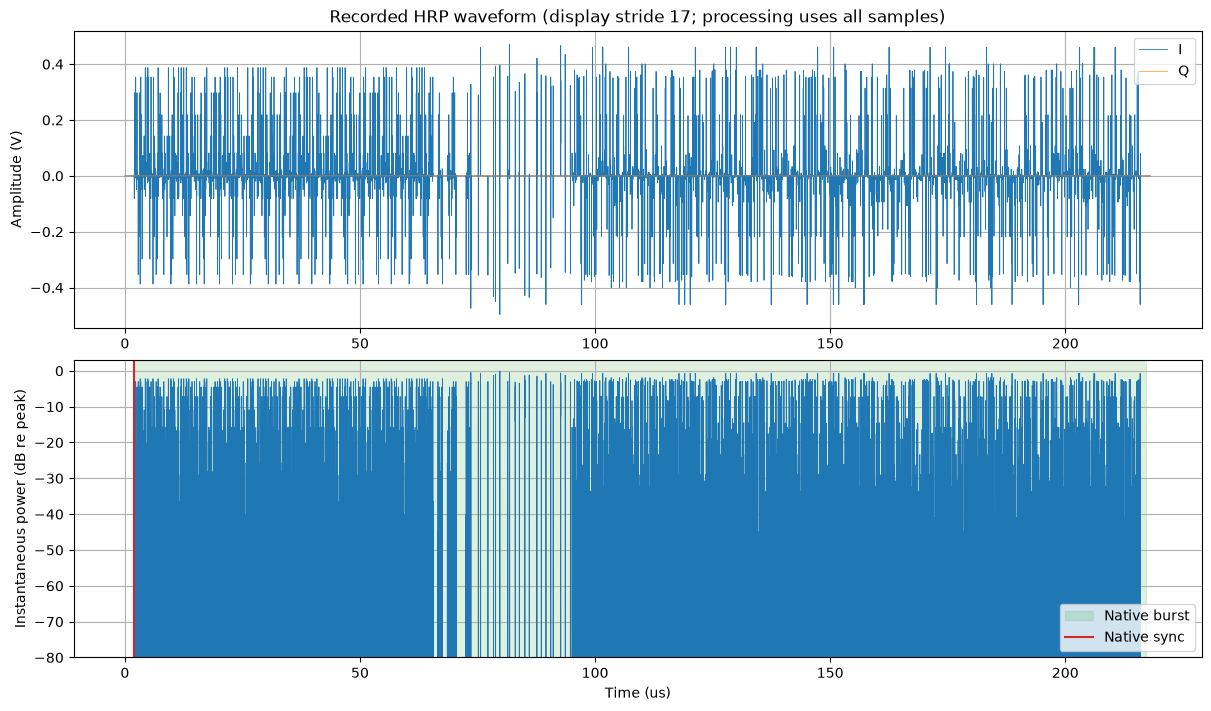

Burst: samples [4060, 433488); duration 215.058 us


In [3]:
# 2. Inspect I/Q and power; overlay the native burst interval.
time_us = np.arange(iq.size) / fs * 1e6
power = np.abs(iq.astype(np.complex128)) ** 2
power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-12))
burst_start = int(result.burstStart)
burst_end = min(iq.size, burst_start + int(result.burstLength))
sync_start = int(result.syncPositionSamples)
period = int(round(result.preambleSymbolPeriodSamples))
assert period > 0 and 0 <= sync_start < iq.size
stride = max(1, iq.size // 25000)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(time_us[::stride], iq.real[::stride], label="I", linewidth=0.6)
axes[0].plot(time_us[::stride], iq.imag[::stride], label="Q", linewidth=0.6, alpha=0.7)
axes[0].set(ylabel="Amplitude (V)", title=f"Recorded HRP waveform (display stride {stride}; processing uses all samples)")
axes[0].legend()
axes[1].plot(time_us[::stride], power_db[::stride], linewidth=0.6)
axes[1].axvspan(burst_start / fs * 1e6, burst_end / fs * 1e6,
                color="tab:green", alpha=0.15, label="Native burst")
axes[1].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[1].set(xlabel="Time (us)", ylabel="Instantaneous power (dB re peak)", ylim=(-80, 3))
axes[1].legend()
plt.show()
print(f"Burst: samples [{burst_start}, {burst_end}); duration {(burst_end - burst_start) / fs * 1e6:.3f} us")

## Native SFD, STS, PHR, and PSDU

**PSDU (PHY Service Data Unit)** is the payload delivered to the PHY. Its transmitted region contains coded pulse symbols; the receiver returns recovered bytes in `psduBytes`. **PPDU** is the complete PHY packet.

**SFD (Start-of-Frame Delimiter)** is a known signed-code sequence after SYNC. Signed correlation locates the frame. **PHR** supplies payload length and rate; legacy/HPRF headers use SECDED. Dynamic EHPRF uses rate/coding PHR1 and CRC-8-protected PHR2.

**STS** is an optional AES-generated ranging sequence, not user data. Every configured segment must pass correlation with the configured key/IV. The default legacy recording has no STS; companion BPRF, HPRF, and EHPRF examples display it.

All plotted intervals come from **native receiver results**, not generator boundaries. Indices are zero-based and follow the acquired pulse lattice, including filter delay. Detail panels show a 500 ns active-pulse window relative to each field start.

The receiver decodes K3/RS, K7, or EHPRF LDPC before returning bytes. `PayloadHex` is compared only afterward. `psduValid` is PHY decoding validity; optional MAC checking has separate `macFcsChecked`/`macFcsValid` flags. EVM is native chip-lattice RMS percent, not a VSA-equivalence claim. STS correlation does not establish secure-ranging authentication.


Native frame: UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt
802.15.4a | coding BCC | STS segments 1
{'burstFound': True, 'syncFound': True, 'frameAttempted': True, 'sfdFound': True, 'stsPresent': False, 'stsValid': False, 'phrValid': True, 'psduValid': True, 'phr1Valid': False, 'ldpcCoding': False, 'macFcsChecked': False, 'macFcsValid': False, 'evmValid': True, 'burstStart': 4060, 'burstLength': 429428, 'syncPositionSamples': 4060, 'syncStart': 3998, 'sfdStart': 130974, 'sfdLength': 15872, 'stsStart': -1, 'stsLength': 0, 'phrStart': 146846, 'phrLength': 43008, 'psduStart': 189854, 'psduLength': 241664, 'psduLengthBytes': 100, 'rsCorrectedSymbols': 0, 'phr2Start': 146846, 'phr2Length': 43008, 'ldpcCorrectedBits': 0, 'syncRho': 0.9913648089237391, 'frequencyErrorHz': -0.0, 'preambleSymbolPeriodSamples': 1984.0, 'sfdRho': 1.0, 'stsRho': 0.0, 'bitRateMbps': 6.81, 'shrEvmRmsPercent': 9.615487720507529e-07, 'stsEvmRmsPercent': 0.0, 'phrEvmRmsPercent': 2.6696789428650634e-06, 'psduEvmRmsPercent': 

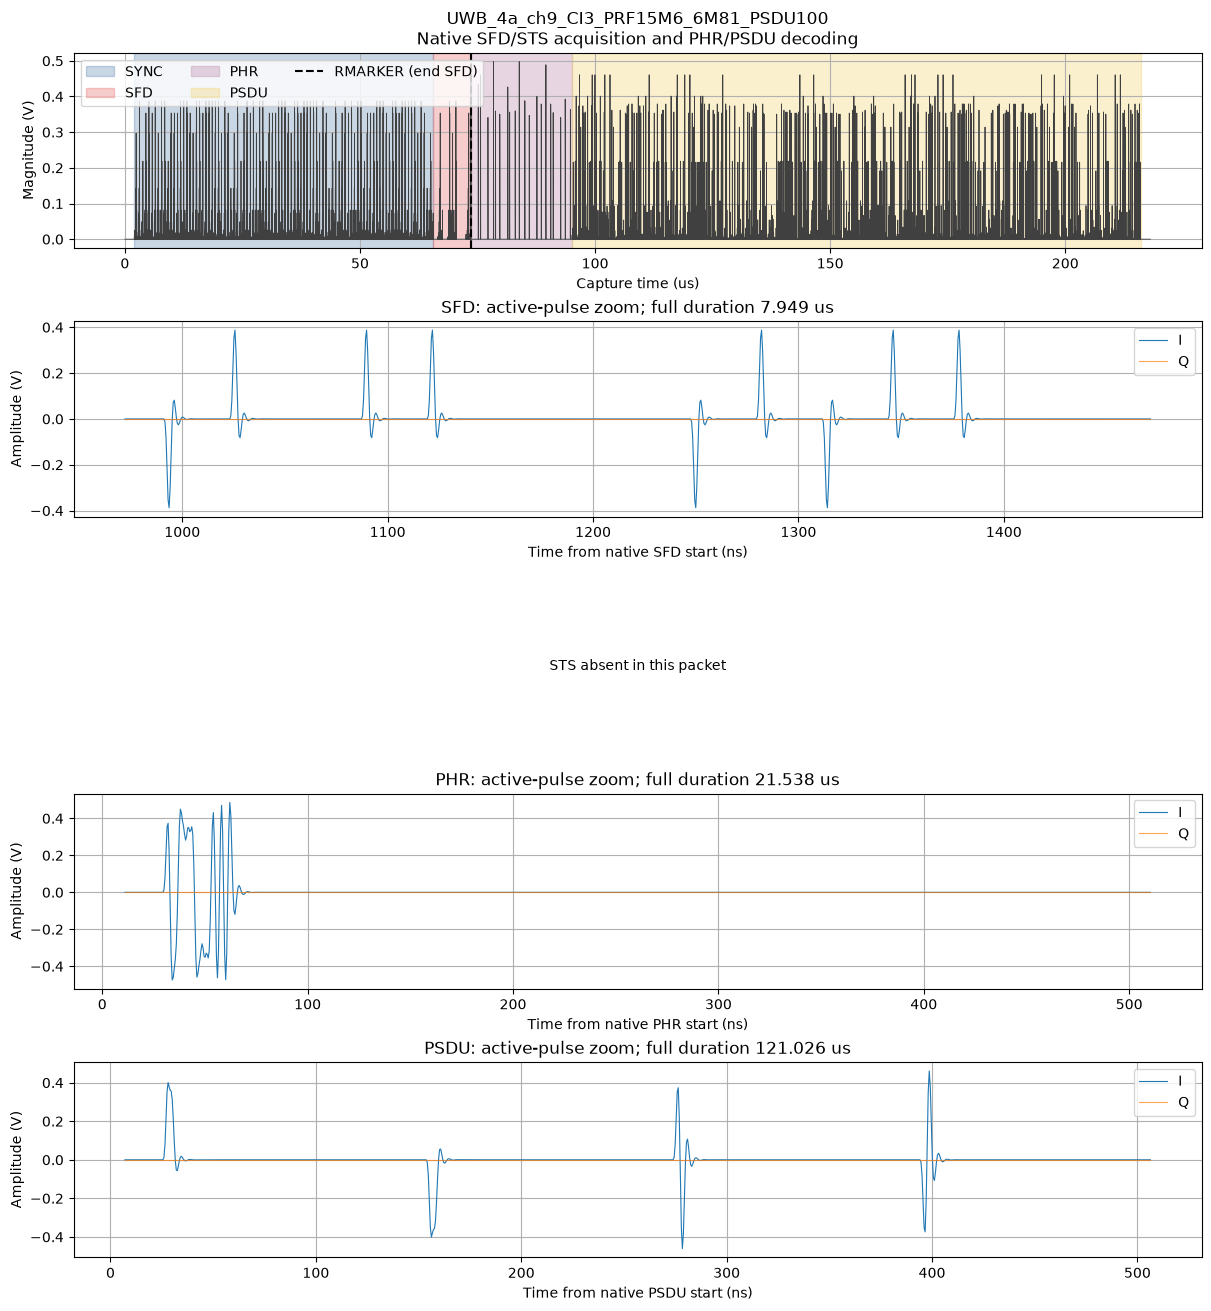

Separate native-decoded STS-enabled example:

Native frame: UWB_4z_BPRF_ch5_CI10_SP1_PSDU127.txt
BPRF | coding BCC | STS segments 1
{'burstFound': True, 'syncFound': True, 'frameAttempted': True, 'sfdFound': True, 'stsPresent': True, 'stsValid': True, 'phrValid': True, 'psduValid': True, 'phr1Valid': False, 'ldpcCoding': False, 'macFcsChecked': False, 'macFcsValid': False, 'evmValid': True, 'burstStart': 4093, 'burstLength': 598780, 'syncPositionSamples': 4093, 'syncStart': 3998, 'sfdStart': 134046, 'sfdLength': 16256, 'stsStart': 150302, 'stsLength': 135168, 'phrStart': 285470, 'phrLength': 5376, 'psduStart': 290846, 'psduLength': 309248, 'psduLengthBytes': 127, 'rsCorrectedSymbols': 0, 'phr2Start': 285470, 'phr2Length': 5376, 'ldpcCorrectedBits': 0, 'syncRho': 0.9905276618684027, 'frequencyErrorHz': -0.0, 'preambleSymbolPeriodSamples': 2032.0, 'sfdRho': 0.9999981594340924, 'stsRho': 0.9999999991905903, 'bitRateMbps': 6.81, 'shrEvmRmsPercent': 2.227548207351514e-06, 'stsEvmRmsPercent'

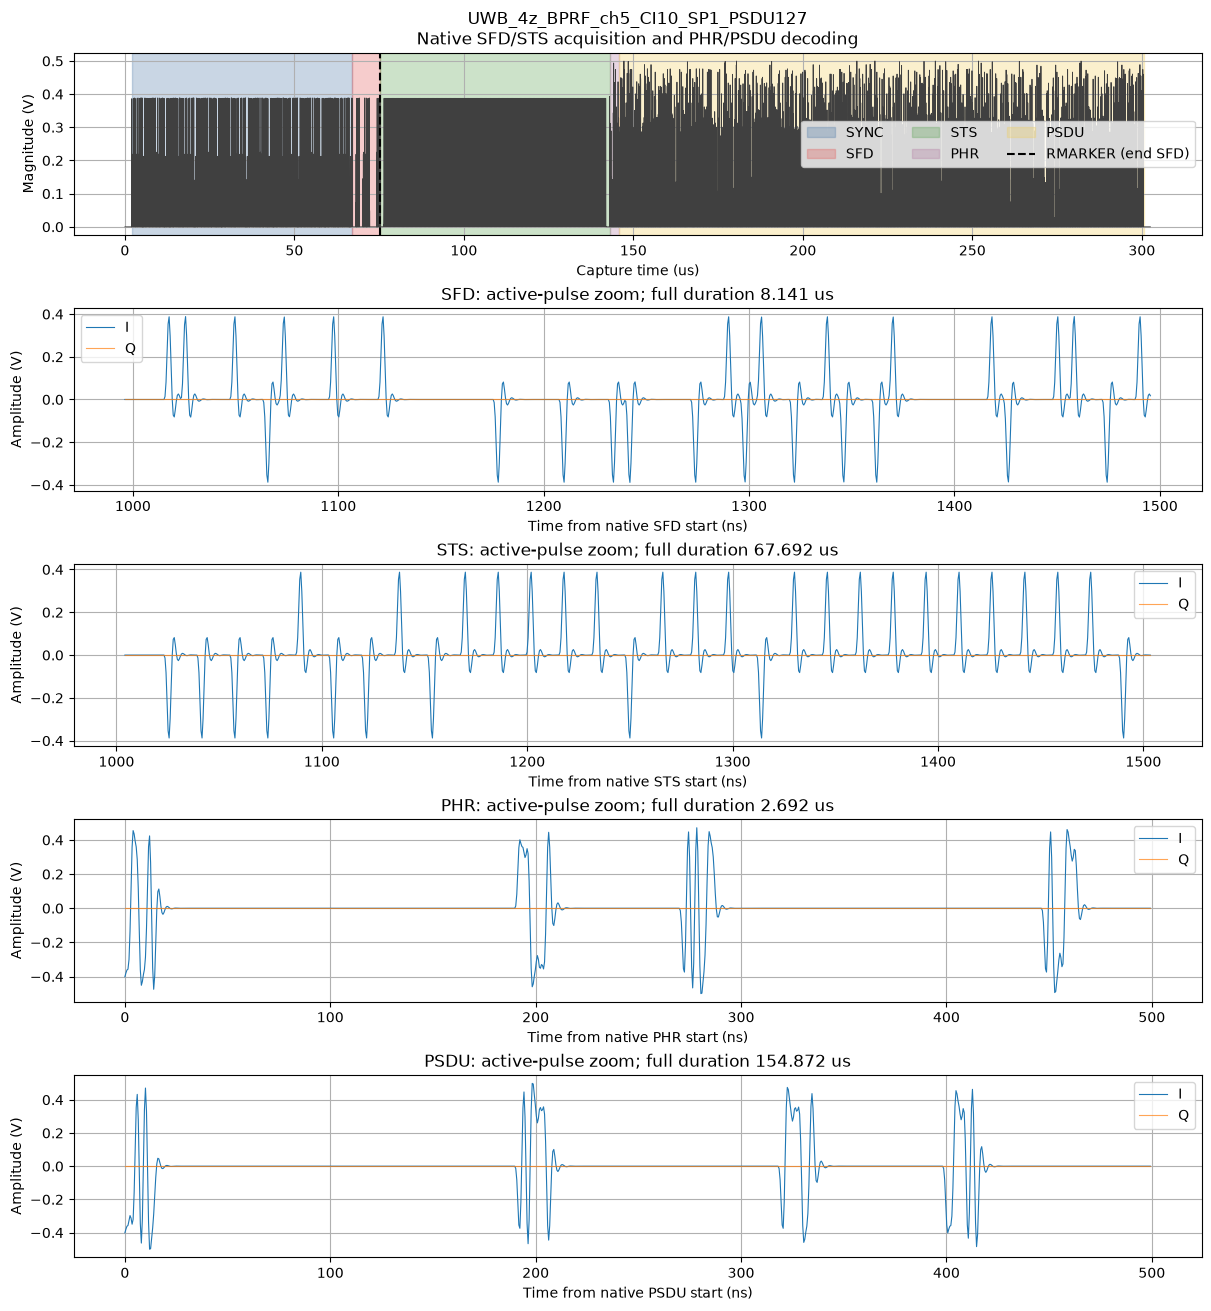


Native frame: UWB_4z_HPRF_ch5_CI27_124M8_PSDU100.txt
HPRF | coding BCC | STS segments 2
{'burstFound': True, 'syncFound': True, 'frameAttempted': True, 'sfdFound': True, 'stsPresent': True, 'stsValid': True, 'phrValid': True, 'psduValid': True, 'phr1Valid': False, 'ldpcCoding': False, 'macFcsChecked': False, 'macFcsValid': False, 'evmValid': True, 'burstStart': 4078, 'burstLength': 535955, 'syncPositionSamples': 4078, 'syncStart': 3998, 'sfdStart': 50590, 'sfdLength': 5824, 'stsStart': 56414, 'stsLength': 268288, 'phrStart': 324702, 'phrLength': 6400, 'psduStart': 331102, 'psduLength': 206336, 'psduLengthBytes': 100, 'rsCorrectedSymbols': 0, 'phr2Start': 324702, 'phr2Length': 6400, 'ldpcCorrectedBits': 0, 'syncRho': 0.9999999998805551, 'frequencyErrorHz': -0.0, 'preambleSymbolPeriodSamples': 1456.0, 'sfdRho': 0.999996706803008, 'stsRho': 0.9999962984634203, 'bitRateMbps': 0.0, 'shrEvmRmsPercent': 1.6972678783398088e-06, 'stsEvmRmsPercent': 1.9089233745196873e-06, 'phrEvmRmsPercent': 1

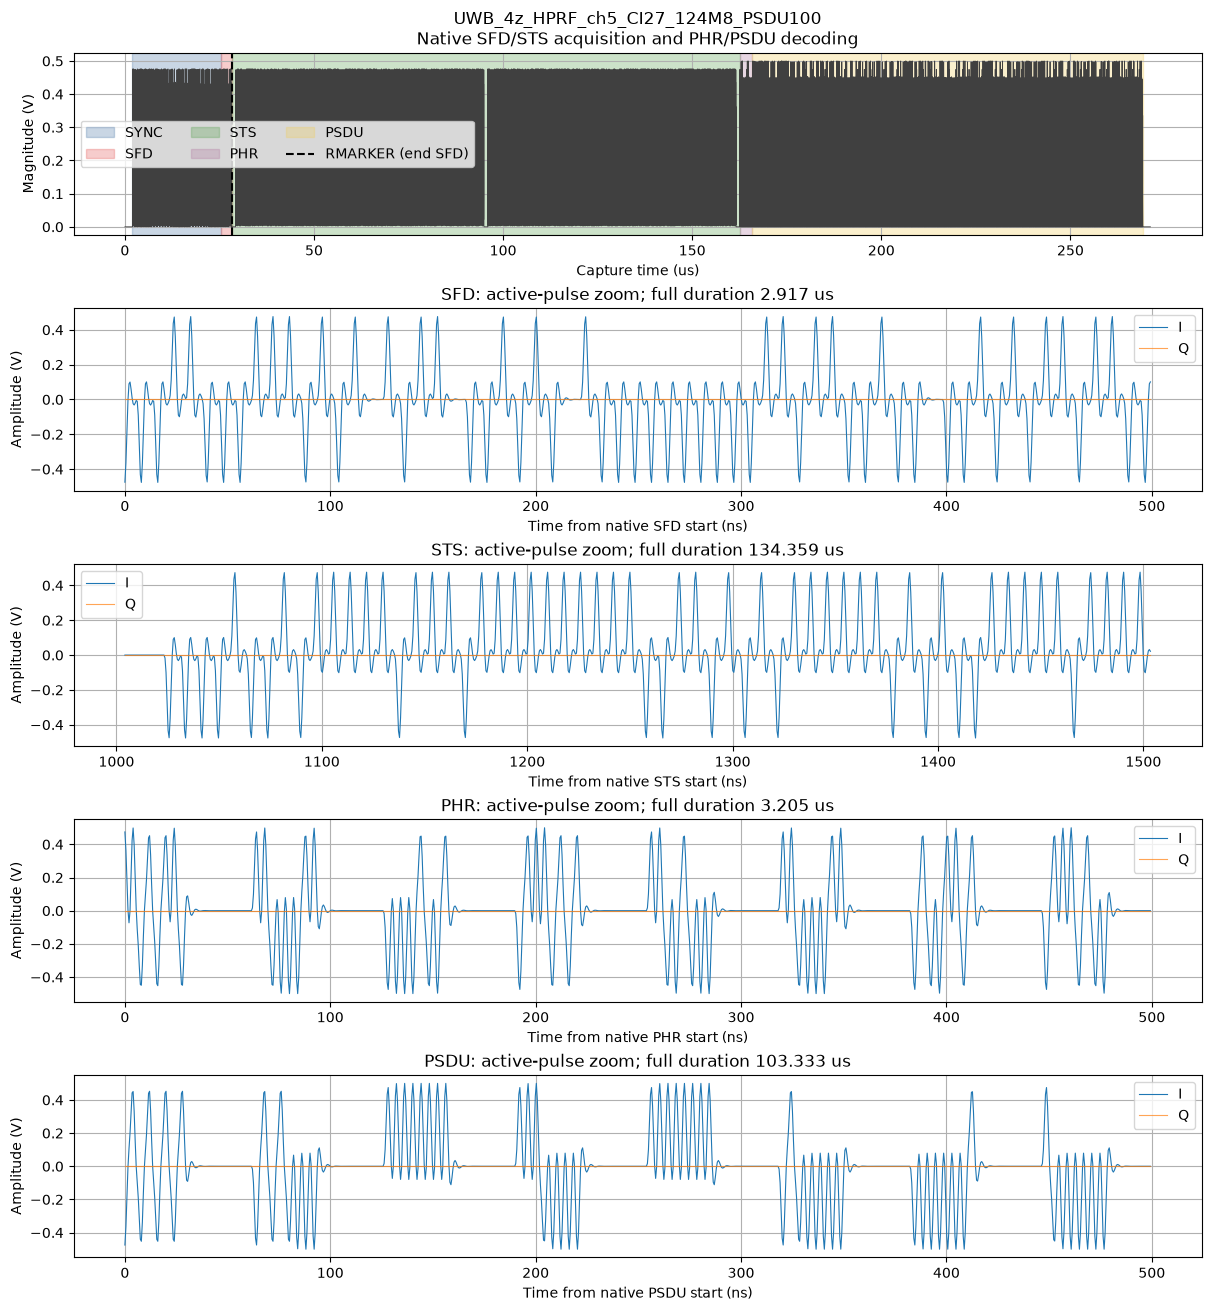


Native frame: UWB_4ab_EHPRF_ch9_124M8_LDPC_PSDU1024.txt
EHPRF | coding LDPC | STS segments 1
{'burstFound': True, 'syncFound': True, 'frameAttempted': True, 'sfdFound': True, 'stsPresent': True, 'stsValid': True, 'phrValid': True, 'psduValid': True, 'phr1Valid': True, 'ldpcCoding': True, 'macFcsChecked': False, 'macFcsValid': False, 'evmValid': True, 'burstStart': 4127, 'burstLength': 390524, 'syncPositionSamples': 4127, 'syncStart': 3998, 'sfdStart': 97182, 'sfdLength': 11648, 'stsStart': 108830, 'stsLength': 135168, 'phrStart': 243998, 'phrLength': 13216, 'psduStart': 257214, 'psduLength': 135520, 'psduLengthBytes': 1024, 'rsCorrectedSymbols': 0, 'phr2Start': 256286, 'phr2Length': 928, 'ldpcCorrectedBits': 0, 'syncRho': 0.9887686681868062, 'frequencyErrorHz': -0.0, 'preambleSymbolPeriodSamples': 1456.0, 'sfdRho': 0.9999967094448421, 'stsRho': 0.9999963013132741, 'bitRateMbps': 124.8, 'shrEvmRmsPercent': 1.7509858266965185e-06, 'stsEvmRmsPercent': 1.7812001102235339e-06, 'phrEvmRmsPe

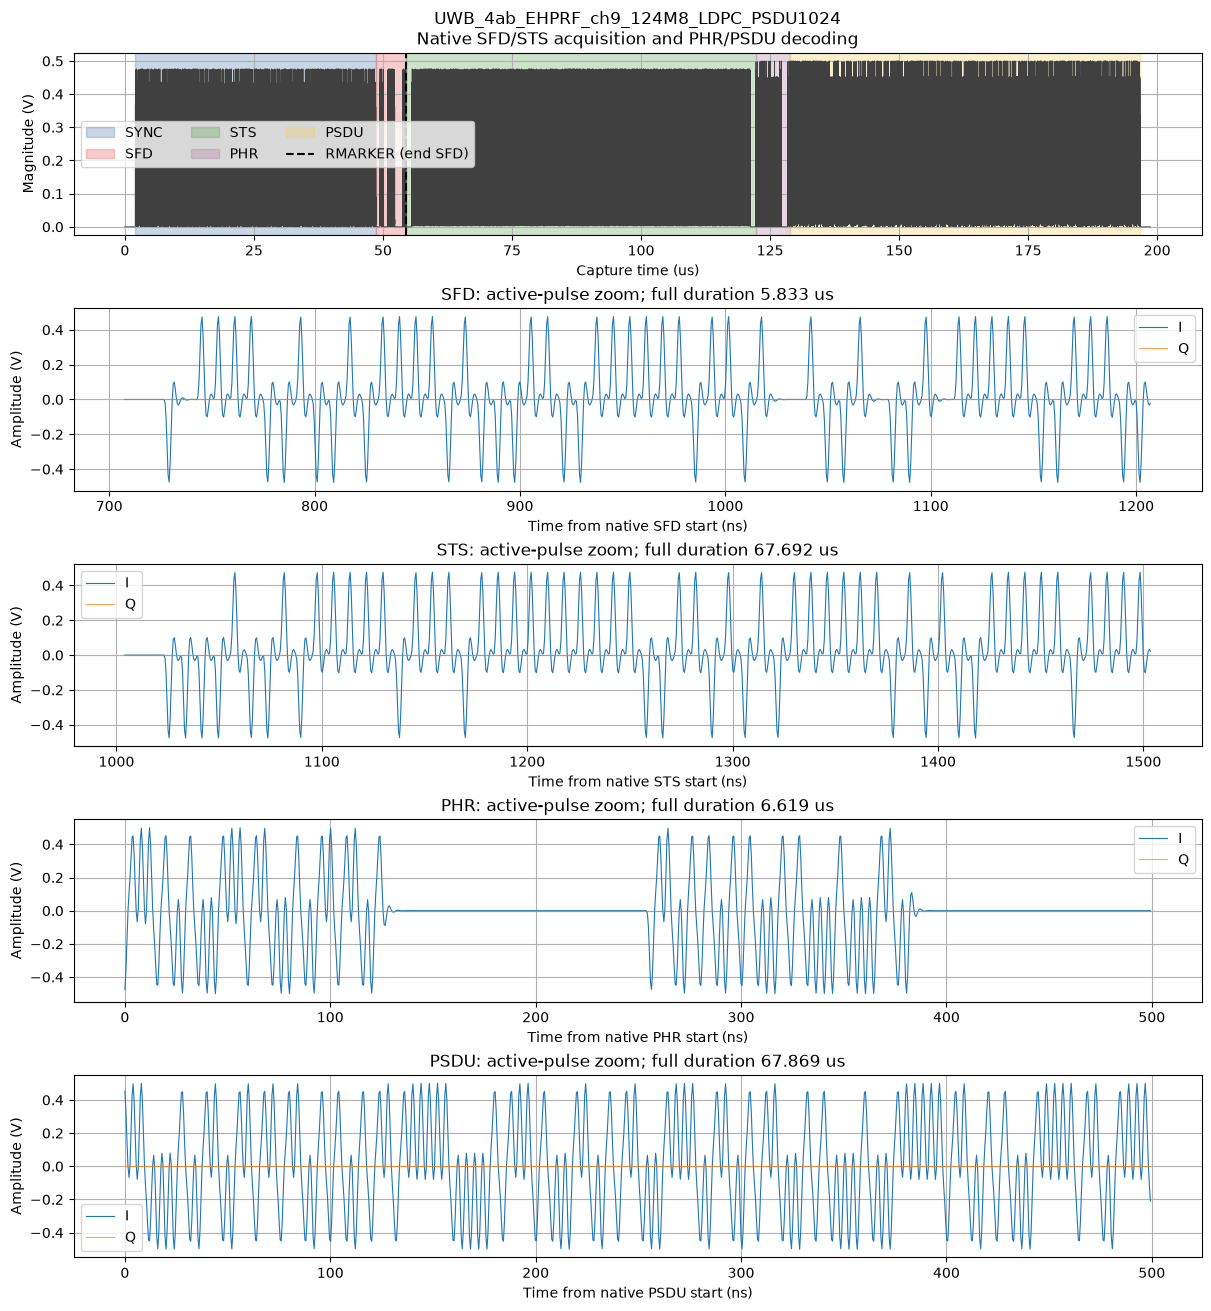

In [4]:
from nrdemod.vsa import load_iq


def native_frame_settings(parameters):
    waveform_mode = parameters["Mode"].upper()
    legacy = waveform_mode == "802.15.4A"
    bit_rate = float(parameters.get("BitRate", 27.2))
    return demod.UwbFrameConfig(
        codeIndex=int(parameters["CodeIndex"]),
        sfdIndex=0 if legacy else int(parameters.get("SfdIndex", 0)),
        stsPacketConfig=0 if legacy else int(parameters["StsPacketConfig"]),
        samplesPerPulse=int(parameters["SamplesPerPulse"]),
        legacy=legacy,
        highRatePhr=float(parameters.get("PHRDataRate", 0.85)) > 1,
        stsKeyHex=parameters.get("STSKey", "4A5572BC90798C8E518D2449092F1B55"),
        stsIvHex=parameters.get("STSUpper96", "68DEBD3A599939DD57FDBB0E")
                 + parameters.get("STSInitialCount", "2A10FAC0"),
        constraintLength=int(parameters.get("ConstraintLength", 7 if waveform_mode == "EHPRF" else 3)),
        numStsSegments=1 if legacy else int(parameters.get("NumSTSSegments", 1)),
        meanPrfMHz=float(parameters.get("MeanPRF", 124.8 if waveform_mode == "EHPRF" and bit_rate <= 7.8 else 249.6)),
        dynamicPhr=parameters.get("DynamicPHR", "1").lower() in ("1", "true"),
        bitRateMbps=bit_rate,
        stsSegmentLength=64 if legacy else int(parameters.get("STSSegmentLength", 64)),
        extraStsGapLength=0 if legacy else int(parameters.get("ExtraSTSGapLength", 0)),
        extraStsGapIndex=0 if legacy else int(parameters.get("ExtraSTSGapIndex", 0)),
        macFcsLength=int(parameters.get("MacFcsLength", 0)),
        legacyRateMbps=float(parameters.get("DataRate", 6.81)),
        legacyMeanPrfMHz=float(parameters.get("MeanPRF", 15.6)) if legacy else 15.6,
        preambleSpread=int(parameters.get("DeltaLength", 0)),
        legacyVsaHopping=parameters.get("LegacyHoppingConvention") == "VsaTrailingPnWindow",
    )


def plot_uwb_fields(waveform_path, field_iq=None, field_fs=None, parameters=None, native_config=None):
    if parameters is None:
        with waveform_path.with_suffix(".para2").open(newline="", encoding="utf-8-sig") as stream:
            parameters = {row[1].strip(): row[3].strip()
                          for row in csv.reader(stream) if len(row) >= 4}
    if field_iq is None:
        field_iq, field_fs = load_iq(str(waveform_path))
    frame_options = native_frame_settings(parameters)
    if native_config is None:
        native_config = demod.Config(
            sampleRate=field_fs, phyMode=native_modes[parameters["Mode"].upper()],
            syncLength=int(parameters["SyncLength"]),
            chipRateHz=float(parameters.get("ChipRate", field_fs / frame_options.samplesPerPulse)))
    decoded = demod.demodulate_uwb_frame(field_iq, native_config, frame_options)
    print(f"\nNative frame: {waveform_path.name}")
    print(f"{parameters['Mode']} | coding {'LDPC' if decoded.ldpcCoding else 'BCC'} | STS segments {frame_options.numStsSegments}")
    print(decoded.as_dict())
    if not decoded.ok:
        print(f"No valid decoded frame: {decoded.error}; no field boundaries inferred.")
        return decoded
    bounds = {"SYNC": (decoded.syncStart, decoded.sfdStart),
              "SFD": (decoded.sfdStart, decoded.sfdStart + decoded.sfdLength)}
    rmarker_sample = int(decoded.sfdStart + decoded.sfdLength)
    assert 0 <= rmarker_sample < field_iq.size
    rmarker_us = rmarker_sample / field_fs * 1e6
    print(f"RMARKER (native end of SFD): sample {rmarker_sample}; capture time {rmarker_us:.6f} us")
    for label, start, length, valid in (
        ("STS", decoded.stsStart, decoded.stsLength, decoded.stsValid),
        ("PHR", decoded.phrStart, decoded.phrLength, decoded.phrValid),
        ("PSDU", decoded.psduStart, decoded.psduLength, decoded.psduValid),
    ):
        if valid and length:
            bounds[label] = (start, start + length)
    assert all(0 <= start < stop <= field_iq.size for start, stop in bounds.values())
    if decoded.phrValid:
        print("Recovered PHR bits:", "".join(str(int(bit)) for bit in decoded.phrBits))
    if decoded.phr1Valid:
        print(f"Dynamic PHR: {decoded.bitRateMbps} Mbps; PHR2 [{decoded.phr2Start}, {decoded.phr2Start + decoded.phr2Length})")
    if decoded.psduValid:
        recovered_bytes = bytes(int(value) for value in decoded.psduBytes)
        assert len(recovered_bytes) == decoded.psduLengthBytes
        print(f"Recovered {len(recovered_bytes)} PSDU bytes; first 32: {recovered_bytes[:32].hex().upper()}")
        if "PayloadHex" in parameters:
            assert recovered_bytes == bytes.fromhex(parameters["PayloadHex"]), "Native PSDU differs from generator reference"
            print("PASS: every recovered byte matches PayloadHex (comparison after native decoding only)")
    print("MAC FCS:", "valid" if decoded.macFcsValid else "failed" if decoded.macFcsChecked else "not requested")
    print("Native chip-lattice EVM (%):", {field: getattr(decoded, field + "EvmRmsPercent")
          for field in ("shr", "sts", "phr", "psdu")})
    field_figure, field_axes = plt.subplots(5, 1, figsize=(12, 13), constrained_layout=True)
    display_step = max(1, field_iq.size // 20000)
    field_axes[0].plot(np.arange(0, field_iq.size, display_step) / field_fs * 1e6,
                       np.abs(field_iq[::display_step]), color="0.25", linewidth=0.6)
    colors = {"SYNC": "#4c78a8", "SFD": "#e45756", "STS": "#59a14f",
              "PHR": "#b279a2", "PSDU": "#f2cf5b"}
    for label, (start, stop) in sorted(bounds.items(), key=lambda item: item[1][0]):
        field_axes[0].axvspan(start / field_fs * 1e6, stop / field_fs * 1e6,
                             color=colors[label], alpha=0.3, label=label)
        print(f"{label:5s}: [{start}, {stop}) native samples")
    field_axes[0].axvline(rmarker_us, color="black", linestyle="--", linewidth=1.5,
                         label="RMARKER (end SFD)", zorder=5)
    field_axes[0].set(xlabel="Capture time (us)", ylabel="Magnitude (V)",
                      title=f"{waveform_path.stem}\nNative SFD/STS acquisition and PHR/PSDU decoding")
    field_axes[0].legend(ncol=3)
    for field_axis, label in zip(field_axes[1:], ("SFD", "STS", "PHR", "PSDU")):
        if label not in bounds:
            field_axis.text(0.5, 0.5, f"{label} absent in this packet", ha="center", va="center",
                            transform=field_axis.transAxes)
            field_axis.set_axis_off()
            continue
        start, stop = bounds[label]
        magnitude = np.abs(field_iq[start:stop])
        active_samples = np.flatnonzero(magnitude >= 0.2 * magnitude.max())
        assert active_samples.size and magnitude.max() > 0
        zoom_start = max(start, start + int(active_samples[0]) - int(round(20e-9 * field_fs)))
        zoom_stop = min(stop, zoom_start + int(round(0.5e-6 * field_fs)))
        segment = field_iq[zoom_start:zoom_stop]
        relative_ns = (np.arange(segment.size) + zoom_start - start) / field_fs * 1e9
        field_axis.plot(relative_ns, segment.real, label="I", linewidth=0.8)
        field_axis.plot(relative_ns, segment.imag, label="Q", linewidth=0.8, alpha=0.7)
        field_axis.set(xlabel=f"Time from native {label} start (ns)", ylabel="Amplitude (V)",
                       title=f"{label}: active-pulse zoom; full duration {(stop - start) / field_fs * 1e6:.3f} us")
        field_axis.legend()
    plt.show()
    return decoded


frame_config = native_frame_settings(settings)
frame_result = plot_uwb_fields(capture, iq, fs, settings, config)
assert frame_result.ok, frame_result.error
if not frame_result.stsPresent:
    sts_example = root / "captures/generated/uwb/UWB_4z_BPRF_ch5_CI10_SP1_PSDU127.txt"
    print("Separate native-decoded STS-enabled example:")
    sts_frame_result = plot_uwb_fields(sts_example)
    assert sts_frame_result.ok and sts_frame_result.stsValid
hprf_example = root / "captures/generated/uwb/UWB_4z_HPRF_ch5_CI27_124M8_PSDU100.txt"
hprf_frame_result = plot_uwb_fields(hprf_example)
assert hprf_frame_result.ok and hprf_frame_result.psduBytes.size == 100
ehprf_example = root / "captures/generated/uwb/UWB_4ab_EHPRF_ch9_124M8_LDPC_PSDU1024.txt"
ehprf_frame_result = plot_uwb_fields(ehprf_example)
assert ehprf_frame_result.ok and ehprf_frame_result.ldpcCoding and ehprf_frame_result.psduBytes.size == 1024


## Digital values become timed, signed analog pulses

A **chip** is a timing slot; a **pulse** is a continuous waveform placed in a slot.
`+1` means transmit a positive reference pulse, `-1` its inverted version,
and `0` no pulse. A negative value does **not** mean negative transmitted energy.

| Field | Small digital example | Mapping shown below |
|---|---|---|
| **SFD** | SFD0 symbols `0,+1,0,-1,+1,0,0,-1` | Each symbol multiplies the whole preamble code. For code 10, the first eight code entries are `+1,+1,0,0,+1,0,-1,+1`. The plot expands the second SFD symbol (`+1`); a `-1` symbol inverts all these pulses, and a `0` symbol is silent. Code entries are four chips apart. |
| **STS** | Illustrative sequence bits `0,1,1,0,1,0` | Pulse sign is $a=1-2b$: `+1,-1,-1,+1,-1,+1`, eight chips apart in BPRF. In an actual frame these bits come from AES with the session key/IV, not from the PSDU. These six bits are illustrative, **not a claimed AES output**. |
| **PSDU** | Four illustrative **coded** pairs `00,01,10,11` | In BPRF BPM-BPSK, the first coded bit selects the early/late half; the second selects the burst polarity. Hopping selects a location within that half, and PN spreading sets individual pulse signs. The picture fixes hop=1 and an illustrative eight-chip PN sequence to isolate those effects. |

**Payload bytes are not pulse signs.** Bytes are serialized least-significant-bit first,
then pass through the applicable FEC and modulation. The four coded pairs below
are an explanatory example, not the first four symbols of the decoded payload.
The SFD code prefix is real; STS/PN examples and Gaussian pulse shapes are illustrative.
HPRF/EHPRF have different data mappings; the data panel specifically shows BPRF at 6.81 Mbps.

For ideal real-baseband pulses, $I(t)=\sum_k a_k p(t-t_k)$ and $Q(t)=0$.
The RF voltage is $v(t)=I(t)\cos(2\pi f_c t)-Q(t)\sin(2\pi f_c t)$.
Changing $a_k$ from +1 to -1 reverses voltage (a 180-degree phase change);
changing $t_k$ moves the pulse in time. Real capture I/Q also includes channel,
filtering, phase rotation and noise. The RF inset uses an illustrative 6.5 GHz carrier,
not a spectral-mask-compliant transmitter model.


Actual decoded PSDU first byte: 0x41
Written MSB first: 01000001; PHY serialization LSB first: 10000010
Byte -> serialized bits -> FEC -> coded pairs -> hopping/spreading -> shaped pulses -> RF


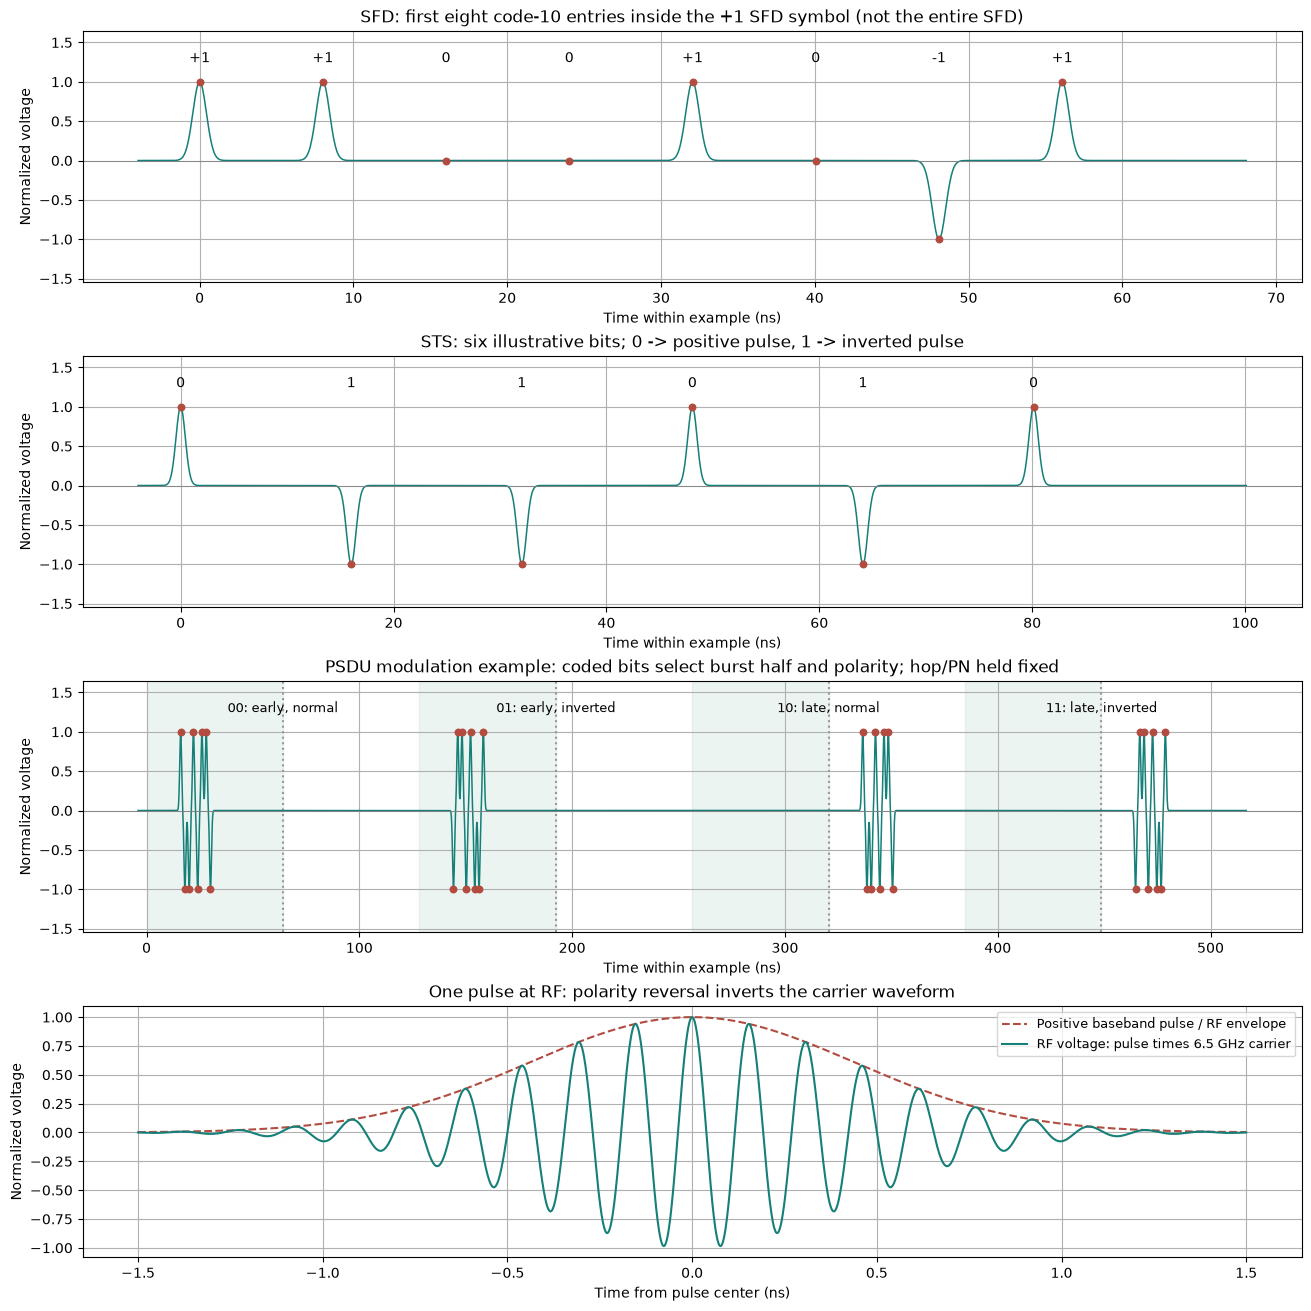

Picture: reports\uwb_digital_to_analog_example.png


In [5]:
from IPython.display import Markdown, display

display(Markdown(r"""
## Digital values become timed, signed analog pulses

A **chip** is a timing slot; a **pulse** is a continuous waveform placed in a slot.
`+1` means transmit a positive reference pulse, `-1` its inverted version,
and `0` no pulse. A negative value does **not** mean negative transmitted energy.

| Field | Small digital example | Mapping shown below |
|---|---|---|
| **SFD** | SFD0 symbols `0,+1,0,-1,+1,0,0,-1` | Each symbol multiplies the whole preamble code. For code 10, the first eight code entries are `+1,+1,0,0,+1,0,-1,+1`. The plot expands the second SFD symbol (`+1`); a `-1` symbol inverts all these pulses, and a `0` symbol is silent. Code entries are four chips apart. |
| **STS** | Illustrative sequence bits `0,1,1,0,1,0` | Pulse sign is $a=1-2b$: `+1,-1,-1,+1,-1,+1`, eight chips apart in BPRF. In an actual frame these bits come from AES with the session key/IV, not from the PSDU. These six bits are illustrative, **not a claimed AES output**. |
| **PSDU** | Four illustrative **coded** pairs `00,01,10,11` | In BPRF BPM-BPSK, the first coded bit selects the early/late half; the second selects the burst polarity. Hopping selects a location within that half, and PN spreading sets individual pulse signs. The picture fixes hop=1 and an illustrative eight-chip PN sequence to isolate those effects. |

**Payload bytes are not pulse signs.** Bytes are serialized least-significant-bit first,
then pass through the applicable FEC and modulation. The four coded pairs below
are an explanatory example, not the first four symbols of the decoded payload.
The SFD code prefix is real; STS/PN examples and Gaussian pulse shapes are illustrative.
HPRF/EHPRF have different data mappings; the data panel specifically shows BPRF at 6.81 Mbps.

For ideal real-baseband pulses, $I(t)=\sum_k a_k p(t-t_k)$ and $Q(t)=0$.
The RF voltage is $v(t)=I(t)\cos(2\pi f_c t)-Q(t)\sin(2\pi f_c t)$.
Changing $a_k$ from +1 to -1 reverses voltage (a 180-degree phase change);
changing $t_k$ moves the pulse in time. Real capture I/Q also includes channel,
filtering, phase rotation and noise. The RF inset uses an illustrative 6.5 GHz carrier,
not a spectral-mask-compliant transmitter model.
"""))

if frame_result.psduValid and frame_result.psduBytes.size:
    example_byte = int(frame_result.psduBytes[0])
    example_bits = [(example_byte >> bit_index) & 1 for bit_index in range(8)]
    print(f"Actual decoded PSDU first byte: 0x{example_byte:02X}")
    print(f"Written MSB first: {example_byte:08b}; PHY serialization LSB first:", ''.join(map(str, example_bits)))
    print("Byte -> serialized bits -> FEC -> coded pairs -> hopping/spreading -> shaped pulses -> RF")
else:
    print("Selected frame has no decoded PSDU; the data modulation example below is illustrative.")

example_chip_ns = 1e9 / 499.2e6
example_sfd_code = np.array([1, 1, 0, 0, 1, 0, -1, 1])
example_sts_bits = np.array([0, 1, 1, 0, 1, 0])
example_pn_bits = np.array([0, 1, 1, 0, 1, 0, 0, 1])
example_coded_pairs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
example_figure, example_axes = plt.subplots(4, 1, figsize=(13, 13), constrained_layout=True)


def draw_example_pulses(axis, pulse_chips, pulse_signs, end_chip, title):
    time_chips = np.arange(-2, end_chip + 2, 0.025)
    shaped = np.zeros(time_chips.size)
    for pulse_chip, pulse_sign in zip(pulse_chips, pulse_signs):
        shaped += pulse_sign * np.exp(-0.5 * ((time_chips - pulse_chip) / 0.22) ** 2)
    assert np.isfinite(shaped).all()
    axis.plot(time_chips * example_chip_ns, shaped, color="#157f78", linewidth=1.1)
    axis.scatter(np.asarray(pulse_chips) * example_chip_ns, pulse_signs,
                 color="#b34c40", s=22, zorder=3, label="Digital pulse coefficients")
    axis.axhline(0, color="0.5", linewidth=0.6)
    axis.set(xlabel="Time within example (ns)", ylabel="Normalized voltage",
             ylim=(-1.55, 1.65), title=title)
    return shaped


sfd_example_wave = draw_example_pulses(
    example_axes[0], 4 * np.arange(8), example_sfd_code, 32,
    "SFD: first eight code-10 entries inside the +1 SFD symbol (not the entire SFD)")
for code_index, code_sign in enumerate(example_sfd_code):
    example_axes[0].text(code_index * 4 * example_chip_ns, 1.25,
                         f"{int(code_sign):+d}" if code_sign else "0", ha="center")
sts_example_signs = 1 - 2 * example_sts_bits
draw_example_pulses(example_axes[1], 8 * np.arange(6), sts_example_signs, 48,
                    "STS: six illustrative bits; 0 -> positive pulse, 1 -> inverted pulse")
for bit_index, sequence_bit in enumerate(example_sts_bits):
    example_axes[1].text(bit_index * 8 * example_chip_ns, 1.25, str(sequence_bit), ha="center")

example_data_positions, example_data_signs = [], []
for symbol_index, (position_bit, polarity_bit) in enumerate(example_coded_pairs):
    symbol_origin = 64 * symbol_index
    burst_origin = symbol_origin + 32 * position_bit + 8
    example_data_positions.extend(burst_origin + np.arange(8))
    example_data_signs.extend((1 - 2 * polarity_bit) * (1 - 2 * example_pn_bits))
    example_axes[2].axvspan(symbol_origin * example_chip_ns, (symbol_origin + 32) * example_chip_ns,
                            color="#67a68c", alpha=0.12)
    example_axes[2].axvline((symbol_origin + 32) * example_chip_ns, color="0.6", linestyle=":")
    example_axes[2].text((symbol_origin + 32) * example_chip_ns, 1.25,
                         f"{position_bit}{polarity_bit}: {'late' if position_bit else 'early'}, "
                         f"{'inverted' if polarity_bit else 'normal'}", ha="center", fontsize=9)
draw_example_pulses(example_axes[2], example_data_positions, example_data_signs, 256,
                    "PSDU modulation example: coded bits select burst half and polarity; hop/PN held fixed")
assert np.array_equal(np.asarray(example_data_signs[:8]), -np.asarray(example_data_signs[8:16]))
assert example_data_positions[16] - example_data_positions[8] == 96

rf_time_ns = np.linspace(-1.5, 1.5, 2401)
rf_envelope = np.exp(-0.5 * (rf_time_ns / (0.22 * example_chip_ns)) ** 2)
rf_voltage = rf_envelope * np.cos(2 * np.pi * 6.5 * rf_time_ns)
example_axes[3].plot(rf_time_ns, rf_envelope, "--", color="#b34c40", label="Positive baseband pulse / RF envelope")
example_axes[3].plot(rf_time_ns, rf_voltage, color="#157f78", label="RF voltage: pulse times 6.5 GHz carrier")
example_axes[3].set(xlabel="Time from pulse center (ns)", ylabel="Normalized voltage",
                    title="One pulse at RF: polarity reversal inverts the carrier waveform")
example_axes[3].legend(loc="upper right", fontsize=9)
example_picture = root / "reports/uwb_digital_to_analog_example.png"
example_figure.savefig(example_picture, dpi=150)
plt.show()
print("Picture:", example_picture.relative_to(root))


## Multipath experiment: the same packet arrives along several paths

We simulate a **static, noiseless complex-baseband channel**:
$y[n]=\sum_\ell a_\ell x[n-d_\ell]$.
Each tap has an excess delay, amplitude and phase; its complex phase includes
carrier propagation phase. Delays are rounded to the capture sample grid and
reported below. Linear convolution retains the full tail: no circular wraparound,
no resampling, no normalization and no added CFO/noise.

The input is the BPRF code-10 SP1 recording, so SFD, keyed STS, PHR and PSDU
can all be checked. Channel taps are **not** passed to the native receiver.
Payload references are used only after decoding. This is a deterministic
sensitivity experiment, not a statistical packet-error-rate or RF/VSA test.

The native EVM model fits a stationary response using SYNC; low residual EVM
can therefore coexist with visibly distorted pulses. It is **not** an independent
measure of multipath strength or proof of a payload equalizer. Inspect STS/PHR
validity and exact byte recovery as well; unavailable EVM is shown as missing.


| Channel | SFD | STS | PHR | PSDU exact | Byte errors | STS rho | PSDU EVM (%) | Timing shift (ns) |
|---|---|---|---|---|---|---|---|---|
| No echo | True | True | True | True | 0 | 1.000 | 0.000 | 0.000 |
| Weak echoes | True | True | True | True | 0 | 1.000 | 0.000 | 0.000 |
| Moderate echoes | True | True | True | True | 0 | 1.000 | 0.000 | 0.000 |
| Strong delayed path | True | False | False | False | N/A | 0.785 | N/A | 16.026 |
| Long echo | True | True | True | True | 0 | 1.000 | 79.884 | 0.000 |

No echo taps: [{'requested_delay_ns': 0, 'delay_samples': 0, 'actual_delay_ns': 0.0, 'amplitude': 1.0, 'phase_deg': 0}]
Weak echoes taps: [{'requested_delay_ns': 0, 'delay_samples': 0, 'actual_delay_ns': 0.0, 'amplitude': 1.0, 'phase_deg': 0}, {'requested_delay_ns': 2, 'delay_samples': 4, 'actual_delay_ns': 2.003205128205128, 'amplitude': 0.25, 'phase_deg': 35}, {'requested_delay_ns': 8, 'delay_samples': 16, 'actual_delay_ns': 8.012820512820513, 'amplitude': 0.12, 'phase_deg': -50}]
Moderate echoes taps: [{'requested_delay_ns': 0, 'delay_samples': 0, 'actual_delay_ns': 0.0, 'amplitude': 1.0, 'phase_deg': 0}, {'requested_delay_ns': 8, 'delay_samples': 16, 'actual_delay_ns': 8.012820512820513, 'amplitude': 0.5, 'phase_deg': 70}, {'requested_delay_ns': 24, 'delay_samples': 48, 'actual_delay_ns': 24.03846153846154, 'amplitude': 0.3, 'phase_deg': -30}]
Strong delayed path taps: [{'requested_delay_ns': 0, 'delay_samples': 0, 'actual_delay_ns': 0.0, 'amplitude': 0.5, 'phase_deg': 0}, {'reques

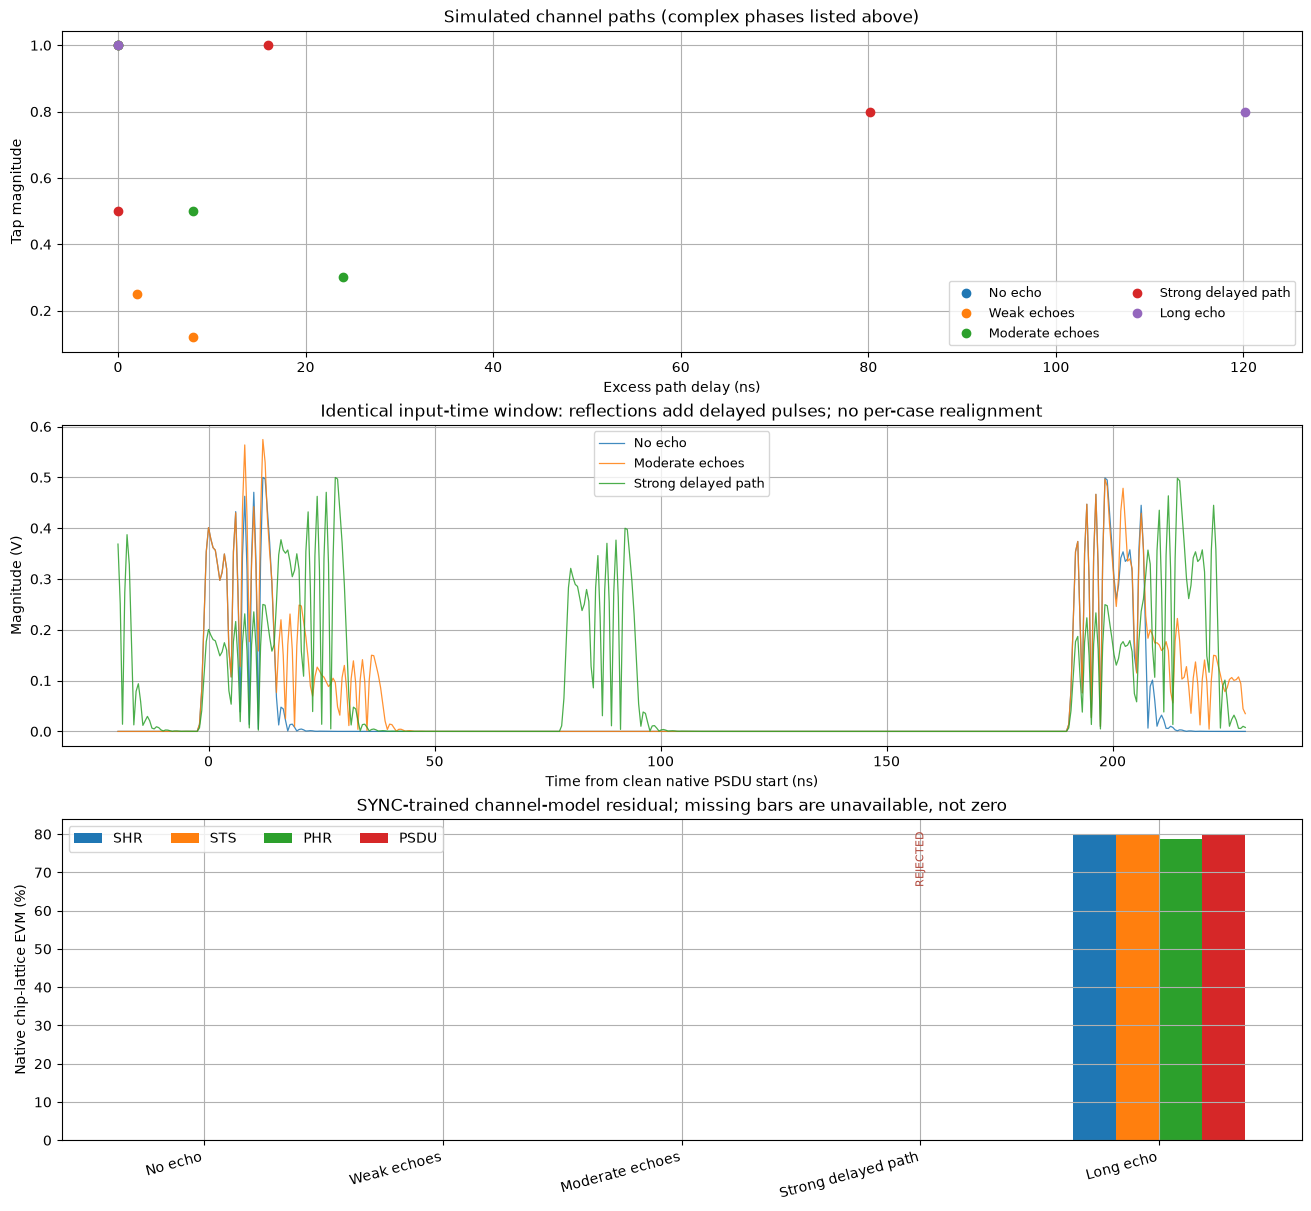

Multipath results: reports\uwb_multipath_example.json reports\uwb_multipath_example.png


In [6]:
import json
from scipy.signal import fftconvolve
from IPython.display import Markdown, display

display(Markdown(r"""
## Multipath experiment: the same packet arrives along several paths

We simulate a **static, noiseless complex-baseband channel**:
$y[n]=\sum_\ell a_\ell x[n-d_\ell]$.
Each tap has an excess delay, amplitude and phase; its complex phase includes
carrier propagation phase. Delays are rounded to the capture sample grid and
reported below. Linear convolution retains the full tail: no circular wraparound,
no resampling, no normalization and no added CFO/noise.

The input is the BPRF code-10 SP1 recording, so SFD, keyed STS, PHR and PSDU
can all be checked. Channel taps are **not** passed to the native receiver.
Payload references are used only after decoding. This is a deterministic
sensitivity experiment, not a statistical packet-error-rate or RF/VSA test.

The native EVM model fits a stationary response using SYNC; low residual EVM
can therefore coexist with visibly distorted pulses. It is **not** an independent
measure of multipath strength or proof of a payload equalizer. Inspect STS/PHR
validity and exact byte recovery as well; unavailable EVM is shown as missing.
"""))

multipath_capture = root / "captures/generated/uwb/UWB_4z_BPRF_ch5_CI10_SP1_PSDU127.txt"
with multipath_capture.with_suffix(".para2").open(newline="", encoding="utf-8-sig") as stream:
    multipath_parameters = {row[1].strip(): row[3].strip()
                            for row in csv.reader(stream) if len(row) >= 4}
multipath_iq, multipath_fs = load_iq(str(multipath_capture))
multipath_options = native_frame_settings(multipath_parameters)
multipath_config = demod.Config(
    sampleRate=multipath_fs, phyMode=demod.UWB_BPRF,
    syncLength=int(multipath_parameters["SyncLength"]),
    chipRateHz=float(multipath_parameters.get("ChipRate", multipath_fs / multipath_options.samplesPerPulse)))
multipath_reference = demod.demodulate_uwb_frame(multipath_iq, multipath_config, multipath_options)
assert multipath_reference.ok and multipath_reference.psduValid and multipath_reference.stsValid
multipath_expected_bytes = bytes(int(value) for value in multipath_reference.psduBytes)
assert multipath_expected_bytes == bytes.fromhex(multipath_parameters["PayloadHex"])

multipath_cases = {
    "No echo": [(0, 1.0, 0)],
    "Weak echoes": [(0, 1.0, 0), (2, 0.25, 35), (8, 0.12, -50)],
    "Moderate echoes": [(0, 1.0, 0), (8, 0.50, 70), (24, 0.30, -30)],
    "Strong delayed path": [(0, 0.50, 0), (16, 1.0, 0), (80, 0.80, 140)],
    "Long echo": [(0, 1.0, 0), (120, 0.80, 180)],
}
multipath_rows, multipath_waveforms, multipath_channels = [], {}, {}
for channel_name, channel_paths in multipath_cases.items():
    channel_delays = [int(round(delay_ns * 1e-9 * multipath_fs)) for delay_ns, _, _ in channel_paths]
    channel_impulse = np.zeros(max(channel_delays) + 1, dtype=np.complex128)
    channel_taps = []
    for delay_samples, (requested_ns, amplitude, phase_deg) in zip(channel_delays, channel_paths):
        channel_impulse[delay_samples] += amplitude * np.exp(1j * np.deg2rad(phase_deg))
        channel_taps.append({"requested_delay_ns": requested_ns, "delay_samples": delay_samples,
                             "actual_delay_ns": delay_samples / multipath_fs * 1e9,
                             "amplitude": amplitude, "phase_deg": phase_deg})
    channel_iq = fftconvolve(multipath_iq, channel_impulse, mode="full").astype(np.complex64)
    assert channel_iq.size == multipath_iq.size + channel_impulse.size - 1
    assert np.isfinite(channel_iq).all()
    if channel_name == "No echo":
        np.testing.assert_allclose(channel_iq, multipath_iq, atol=1e-6 * np.max(np.abs(multipath_iq)), rtol=1e-6)
    channel_result = demod.demodulate_uwb_frame(channel_iq, multipath_config, multipath_options)
    channel_bytes = bytes(int(value) for value in channel_result.psduBytes) if channel_result.psduValid else None
    exact_bytes = channel_bytes == multipath_expected_bytes
    byte_errors = (sum(left != right for left, right in zip(channel_bytes, multipath_expected_bytes))
                   + abs(len(channel_bytes) - len(multipath_expected_bytes))) if channel_bytes is not None else None
    channel_evm = {field: float(getattr(channel_result, field + "EvmRmsPercent"))
                   if channel_result.evmValid and valid else None
                   for field, valid in (("shr", channel_result.sfdFound), ("sts", channel_result.stsValid),
                                        ("phr", channel_result.phrValid), ("psdu", channel_result.psduValid))}
    channel_row = {"channel": channel_name, "taps": channel_taps, "ok": bool(channel_result.ok),
                   "sfd_found": bool(channel_result.sfdFound), "sts_valid": bool(channel_result.stsValid),
                   "phr_valid": bool(channel_result.phrValid), "psdu_valid": bool(channel_result.psduValid),
                   "exact_psdu": exact_bytes, "byte_errors": byte_errors,
                   "sfd_rho": float(channel_result.sfdRho), "sts_rho": float(channel_result.stsRho),
                   "frequency_error_hz": float(channel_result.frequencyErrorHz),
                   "timing_shift_ns": (channel_result.syncStart - multipath_reference.syncStart) / multipath_fs * 1e9
                                      if channel_result.sfdFound else None,
                   "rs_corrected_symbols": int(channel_result.rsCorrectedSymbols),
                   "evm_percent": channel_evm, "error": channel_result.error}
    multipath_rows.append(channel_row)
    multipath_channels[channel_name] = channel_impulse
    multipath_waveforms[channel_name] = channel_iq
assert multipath_rows[0]["ok"] and multipath_rows[0]["exact_psdu"] and multipath_rows[0]["sts_valid"]

multipath_table = ["| Channel | SFD | STS | PHR | PSDU exact | Byte errors | STS rho | PSDU EVM (%) | Timing shift (ns) |",
                   "|---|---|---|---|---|---|---|---|---|"]
for channel_row in multipath_rows:
    evm_text = "N/A" if channel_row["evm_percent"]["psdu"] is None else f"{channel_row['evm_percent']['psdu']:.3f}"
    timing_text = "N/A" if channel_row["timing_shift_ns"] is None else f"{channel_row['timing_shift_ns']:.3f}"
    errors_text = "N/A" if channel_row["byte_errors"] is None else str(channel_row["byte_errors"])
    multipath_table.append(f"| {channel_row['channel']} | {channel_row['sfd_found']} | {channel_row['sts_valid']} | "
                           f"{channel_row['phr_valid']} | {channel_row['exact_psdu']} | {errors_text} | "
                           f"{channel_row['sts_rho']:.3f} | {evm_text} | {timing_text} |")
display(Markdown("\n".join(multipath_table)))
for channel_row in multipath_rows:
    print(channel_row["channel"], "taps:", channel_row["taps"])
    if channel_row["error"]:
        print("  Receiver rejected:", channel_row["error"])

multipath_figure, multipath_axes = plt.subplots(3, 1, figsize=(13, 12), constrained_layout=True)
for channel_name, channel_impulse in multipath_channels.items():
    nonzero_taps = np.flatnonzero(np.abs(channel_impulse) > 0)
    multipath_axes[0].plot(nonzero_taps / multipath_fs * 1e9, np.abs(channel_impulse[nonzero_taps]),
                           "o", label=channel_name)
multipath_axes[0].set(xlabel="Excess path delay (ns)", ylabel="Tap magnitude",
                      title="Simulated channel paths (complex phases listed above)")
multipath_axes[0].legend(ncol=2, fontsize=9)
multipath_zoom_start = max(0, multipath_reference.psduStart - int(round(20e-9 * multipath_fs)))
multipath_zoom_stop = min(multipath_iq.size, multipath_zoom_start + int(round(250e-9 * multipath_fs)))
for channel_name in ("No echo", "Moderate echoes", "Strong delayed path"):
    channel_iq = multipath_waveforms[channel_name]
    multipath_axes[1].plot((np.arange(multipath_zoom_start, multipath_zoom_stop) - multipath_reference.psduStart)
                           / multipath_fs * 1e9, np.abs(channel_iq[multipath_zoom_start:multipath_zoom_stop]),
                           linewidth=0.9, alpha=0.85, label=channel_name)
multipath_axes[1].set(xlabel="Time from clean native PSDU start (ns)", ylabel="Magnitude (V)",
                      title="Identical input-time window: reflections add delayed pulses; no per-case realignment")
multipath_axes[1].legend(fontsize=9)
multipath_positions = np.arange(len(multipath_rows))
for field_index, field in enumerate(("shr", "sts", "phr", "psdu")):
    multipath_axes[2].bar(multipath_positions + (field_index - 1.5) * 0.18,
                          [np.nan if row["evm_percent"][field] is None else row["evm_percent"][field]
                           for row in multipath_rows], width=0.18, label=field.upper())
for row_index, channel_row in enumerate(multipath_rows):
    if not channel_row["ok"]:
        multipath_axes[2].text(row_index, 0.96, "REJECTED", rotation=90, ha="center", va="top",
                               transform=multipath_axes[2].get_xaxis_transform(), color="#b34c40", fontsize=8)
multipath_axes[2].set_xticks(multipath_positions, list(multipath_cases), rotation=15, ha="right")
multipath_axes[2].set(ylabel="Native chip-lattice EVM (%)",
                      title="SYNC-trained channel-model residual; missing bars are unavailable, not zero")
multipath_axes[2].legend(ncol=4)
multipath_picture = root / "reports/uwb_multipath_example.png"
multipath_figure.savefig(multipath_picture, dpi=150)
plt.show()
multipath_report = root / "reports/uwb_multipath_example.json"
multipath_report.write_text(json.dumps({"capture": multipath_capture.relative_to(root).as_posix(),
                                       "sample_rate_hz": multipath_fs, "noise_added": False,
                                       "normalization": "none", "rows": multipath_rows}, indent=2, allow_nan=False) + "\n",
                            encoding="utf-8")
print("Multipath results:", multipath_report.relative_to(root), multipath_picture.relative_to(root))

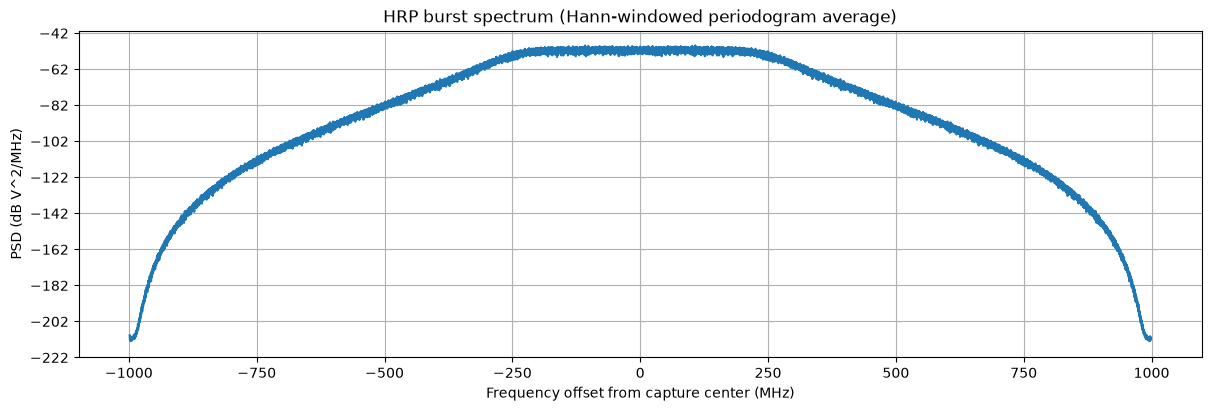

In [7]:
# 3. Estimate the two-sided complex-baseband power spectral density.
fig, axis = plt.subplots(figsize=(12, 4), constrained_layout=True)
axis.psd(iq[burst_start:burst_end], NFFT=8192, Fs=fs / 1e6,
         sides="twosided", scale_by_freq=True)
axis.set(title="HRP burst spectrum (Hann-windowed periodogram average)",
         xlabel="Frequency offset from capture center (MHz)", ylabel="PSD (dB V^2/MHz)")
plt.show()

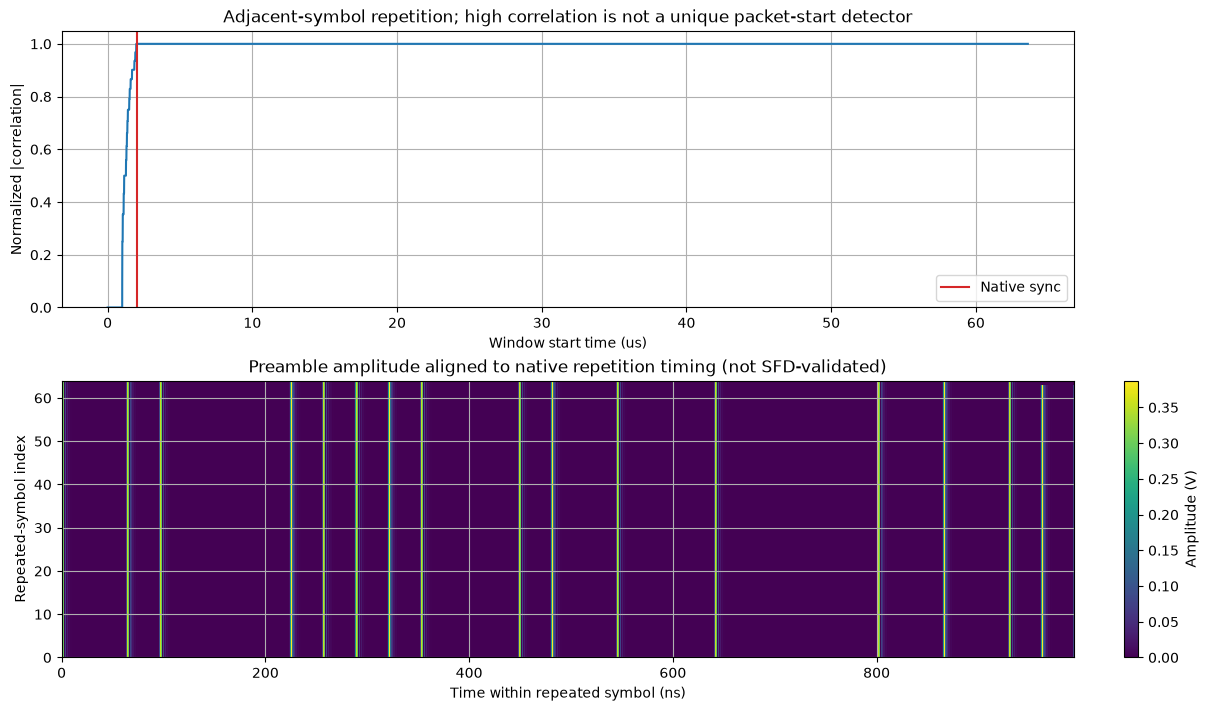

Native period: 1984 samples = 993.590 ns
Native sync rho: 0.991365; independent repetition maximum: 1.000000


In [8]:
# 4. Measure normalized repetition correlation between adjacent preamble symbols.
# This is a notebook diagnostic, not an internal native-core trace.
window_count = min(64 * period, iq.size - 2 * period)
assert window_count > 0
first = iq[:window_count + period].astype(np.complex128)
second = iq[period:window_count + 2 * period].astype(np.complex128)

def moving_sum(values, length):
    cumulative = np.concatenate(([0], np.cumsum(values)))
    return cumulative[length:] - cumulative[:-length]

cross = moving_sum(np.conj(first) * second, period)
energy_first = moving_sum(np.abs(first) ** 2, period).real
energy_second = moving_sum(np.abs(second) ** 2, period).real
denominator = np.sqrt(np.maximum(energy_first, 0) * np.maximum(energy_second, 0))
rho = np.divide(np.abs(cross), denominator, out=np.zeros_like(denominator),
                where=denominator > np.max(denominator) * 1e-8)
rho = np.clip(rho, 0, 1)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(np.arange(rho.size) / fs * 1e6, rho)
axes[0].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[0].set(xlabel="Window start time (us)", ylabel="Normalized |correlation|", ylim=(0, 1.05),
            title="Adjacent-symbol repetition; high correlation is not a unique packet-start detector")
axes[0].legend()
preamble_count = min(config.syncLength, (iq.size - sync_start) // period)
assert preamble_count >= 2
preamble = iq[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
image = axes[1].imshow(np.abs(preamble), aspect="auto", origin="lower", interpolation="nearest",
                        extent=(0, period / fs * 1e9, 0, preamble_count), cmap="viridis")
axes[1].set(xlabel="Time within repeated symbol (ns)", ylabel="Repeated-symbol index",
            title="Preamble amplitude aligned to native repetition timing (not SFD-validated)")
fig.colorbar(image, ax=axes[1], label="Amplitude (V)")
plt.show()
assert np.isfinite(rho).all()
print(f"Native period: {period} samples = {period / fs * 1e9:.3f} ns")
print(f"Native sync rho: {result.syncRho:.6f}; independent repetition maximum: {rho.max():.6f}")

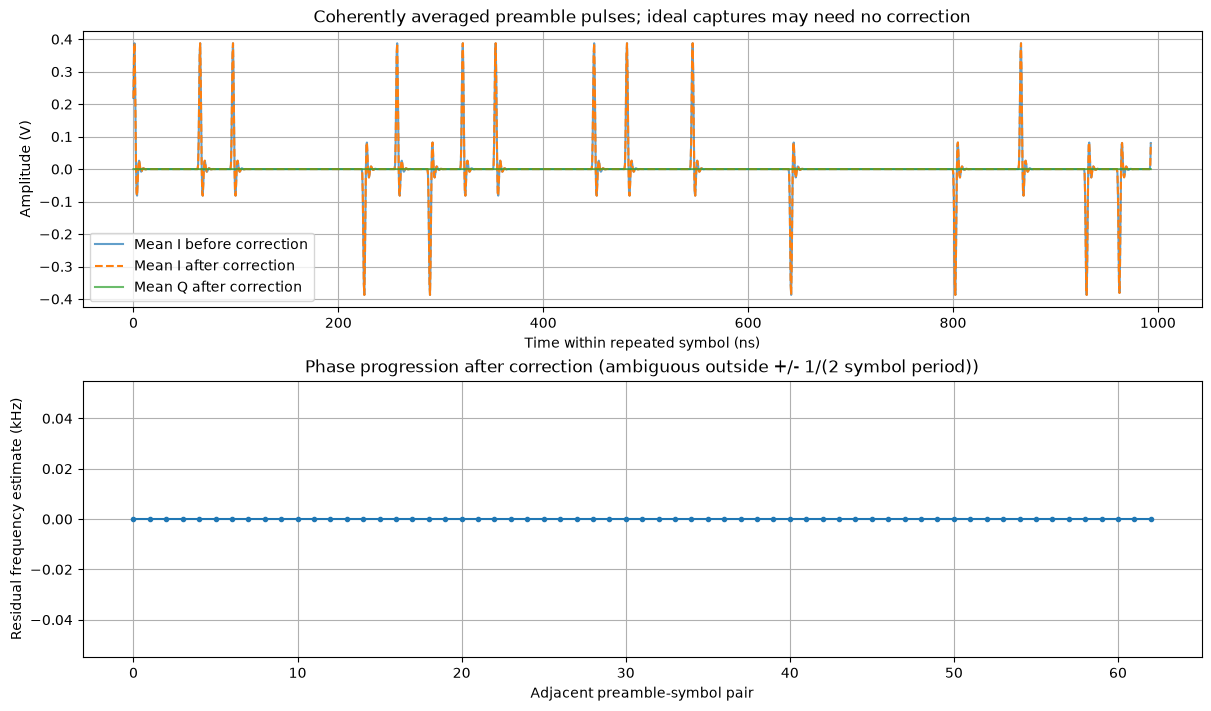

Applied native frequency correction: -0.000 Hz
Median repetition-based residual: 0.000 Hz

Receiver summary
Burst detected: True; preamble synchronized: True
Sync sample: 4060; sync metric: 0.991365
Frame valid: True; SFD: True; STS present/valid: False/False
PHR valid: True; PSDU valid: True; decoded bytes: 100
Native RS corrected symbols: 0
MAC CRC/FCS and native EVM: not implemented


In [9]:
frequency_error_hz = float(result.frequencyErrorHz)
corrected = iq * np.exp(-2j * np.pi * frequency_error_hz * np.arange(iq.size) / fs)
aligned = corrected[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
average_before = preamble.mean(axis=0)
average_after = aligned.mean(axis=0)
phase_step = np.angle(np.sum(np.conj(aligned[:-1]) * aligned[1:], axis=1))
residual_hz = phase_step * fs / (2 * np.pi * period)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
within_ns = np.arange(period) / fs * 1e9
axes[0].plot(within_ns, average_before.real, label="Mean I before correction", alpha=0.7)
axes[0].plot(within_ns, average_after.real, "--", label="Mean I after correction")
axes[0].plot(within_ns, average_after.imag, label="Mean Q after correction", alpha=0.7)
axes[0].set(xlabel="Time within repeated symbol (ns)", ylabel="Amplitude (V)",
            title="Coherently averaged preamble pulses; ideal captures may need no correction")
axes[0].legend()
axes[1].plot(np.arange(residual_hz.size), residual_hz / 1e3, marker=".")
axes[1].set(xlabel="Adjacent preamble-symbol pair", ylabel="Residual frequency estimate (kHz)",
            title="Phase progression after correction (ambiguous outside +/- 1/(2 symbol period))")
plt.show()
assert np.isfinite(corrected).all() and np.isfinite(residual_hz).all()
print(f"Applied native frequency correction: {frequency_error_hz:.3f} Hz")
print(f"Median repetition-based residual: {np.median(residual_hz):.3f} Hz")

print("\nReceiver summary")
print(f"Burst detected: {result.burstFound}; preamble synchronized: {result.syncFound}")
print(f"Sync sample: {sync_start}; sync metric: {result.syncRho:.6f}")
print(f"Frame valid: {frame_result.ok}; SFD: {frame_result.sfdFound}; STS present/valid: {frame_result.stsPresent}/{frame_result.stsValid}")
print(f"PHR valid: {frame_result.phrValid}; PSDU valid: {frame_result.psduValid}; decoded bytes: {frame_result.psduBytes.size}")
if frame_result.psduValid:
    print(f"Native RS corrected symbols: {frame_result.rsCorrectedSymbols}")
print("MAC CRC/FCS and native EVM: not implemented")

## Native C-ABI Verification and 89600 Correlation

The checks below exercise **all nine bundled legacy/BPRF/HPRF/EHPRF frames**. Every PSDU byte must match its independent reference; STS-only SP3 must not claim payload validity. Wrong keys, truncation, SFD damage, and missing STS segments reject. A +25 kHz shift preserves the selected PSDU. A 10% payload-amplitude change must produce approximately 10% native EVM without changing decoded bytes.

Native C++ tests additionally cover all nine recordings under CFO, K7 and LDPC error recovery, and injected RS-symbol errors (one/four corrected, the tested five-error pattern rejected). CRC-16 and CRC-32 known vectors pass, and random-PSDU FCS requests reject. The separate `UwbFrameApiTest.py` suite checks 77 independently generated frames, all 32 preamble tables, LDPC shortening boundaries, valid FCS frames, rate/SFD/STS settings, and both previous C layouts.

Saved VSA measurements require matching path, waveform name, and SHA256. SHR/CFO are always required; PHR/PSDU and STS depend on packet configuration. Missing, nonfinite, and sentinel results reject. Limits: CFO agreement within **100 Hz**, SHR/STS NRMSE at most **0.5%**, PHR/PSDU at most **2%**.

Native chip-lattice EVM and VSA NRMSE remain **different measurements**, not interchangeable columns. Inventory coverage remains **15 native synchronization passes, nine native frame passes, 12 saved VSA passes, zero VSA failures, and three VSA-unsupported EHPRF cases**. Six TDC inventory captures have synchronization checks only. This is interoperability evidence, not independent IEEE certification.

Keep `run_vsa_measurement=False` to reuse hash-matched saved measurements. Set it to `True` for a new replay through a running VSA. No fresh instrument sweep is implied by the saved comparisons.

Shared native/VSA capture: UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt
PASS native frame: {'capture': 'UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt', 'mode': '802.15.4A', 'coding': 'BCC', 'constraint_length': 3, 'sts_segments': 1, 'decoded_bytes': 100, 'sts_valid': False, 'mac_fcs_checked': False, 'mac_fcs_valid': False, 'ldpc_corrected_bits': 0, 'native_evm_percent': {'shr': 9.615487720507529e-07, 'sts': 0.0, 'phr': 2.6696789428650634e-06, 'psdu': 1.3329872653148303e-06}, 'passed': True}
PASS native frame: {'capture': 'UWB_4ab_EHPRF_ch5_7M8_LDPC_PSDU127.txt', 'mode': 'EHPRF', 'coding': 'LDPC', 'constraint_length': 7, 'sts_segments': 1, 'decoded_bytes': 127, 'sts_valid': True, 'mac_fcs_checked': False, 'mac_fcs_valid': False, 'ldpc_corrected_bits': 0, 'native_evm_percent': {'shr': 1.7509858266965185e-06, 'sts': 1.7812001102235339e-06, 'phr': 1.8442612275490153e-06, 'psdu': 1.8594733507240794e-06}, 'passed': True}
PASS native frame: {'capture': 'UWB_4ab_EHPRF_ch9_124M8_LDPC_PSDU1024.txt', 'mode'

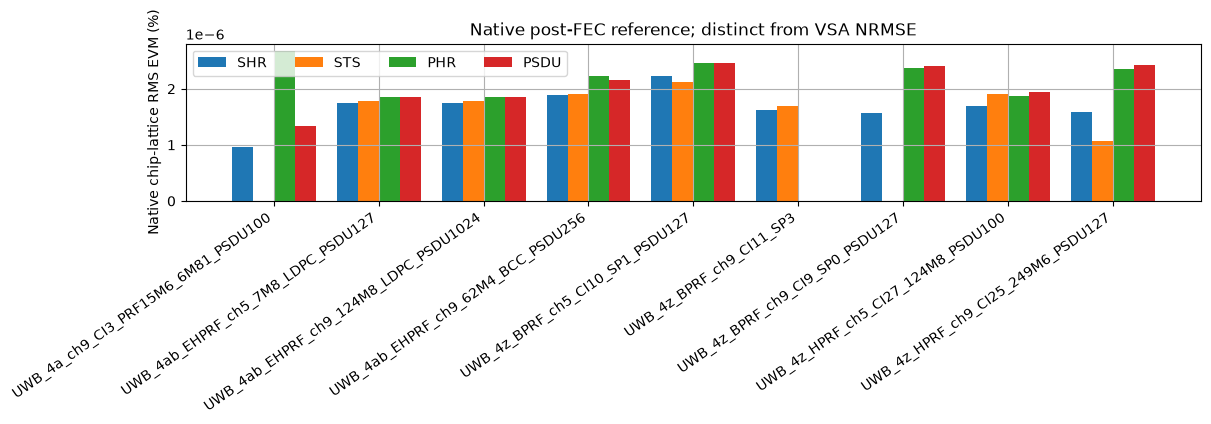

In [10]:
reference_capture = capture
reference_iq, reference_fs = iq, fs
reference_config = config
reference_result = result
assert reference_result.ok and reference_result.burstFound and reference_result.syncFound
print(f"Shared native/VSA capture: {reference_capture.name}")

injected_cfo_hz = 25000.0
shifted_reference = reference_iq * np.exp(2j * np.pi * injected_cfo_hz * np.arange(reference_iq.size) / reference_fs)
shifted_reference_result = demod.demodulate(demod.UWB_HRP, shifted_reference, reference_config)
assert shifted_reference_result.ok and shifted_reference_result.syncFound
measured_cfo_shift_hz = shifted_reference_result.frequencyErrorHz - reference_result.frequencyErrorHz
np.testing.assert_allclose(measured_cfo_shift_hz, injected_cfo_hz, atol=100.0, rtol=0)
empty_reference_result = demod.demodulate(demod.UWB_HRP, np.empty(0, dtype=np.complex64), reference_config)
assert not empty_reference_result.ok
shifted_frame = demod.demodulate_uwb_frame(shifted_reference, config, frame_config)
assert shifted_frame.ok and np.array_equal(shifted_frame.psduBytes, frame_result.psduBytes)
empty_frame = demod.demodulate_uwb_frame(np.empty(0, dtype=np.complex64), config, frame_config)
assert not empty_frame.ok

frame_checks = []
for frame_path in sorted((root / "captures/generated/uwb").glob("*.txt")):
    with frame_path.with_suffix(".para2").open(newline="", encoding="utf-8-sig") as stream:
        frame_parameters = {row[1].strip(): row[3].strip()
                            for row in csv.reader(stream) if len(row) >= 4}
    frame_mode = frame_parameters["Mode"].upper()
    if frame_mode not in native_modes:
        continue
    frame_iq, frame_fs = load_iq(str(frame_path))
    frame_options = native_frame_settings(frame_parameters)
    frame_phy = demod.Config(sampleRate=frame_fs, phyMode=native_modes[frame_mode],
                             syncLength=int(frame_parameters["SyncLength"]),
                             chipRateHz=float(frame_parameters.get("ChipRate", frame_fs / frame_options.samplesPerPulse)))
    checked_frame = demod.demodulate_uwb_frame(frame_iq, frame_phy, frame_options)
    assert checked_frame.ok, (frame_path.name, checked_frame.error)
    assert checked_frame.evmValid
    assert checked_frame.shrEvmRmsPercent < 0.1
    if checked_frame.psduValid:
        decoded_bytes = bytes(int(value) for value in checked_frame.psduBytes)
        assert decoded_bytes == bytes.fromhex(frame_parameters["PayloadHex"])
        assert checked_frame.phrEvmRmsPercent < 0.1 and checked_frame.psduEvmRmsPercent < 0.1
        truncated_frame = demod.demodulate_uwb_frame(frame_iq[:checked_frame.psduStart + 100], frame_phy, frame_options)
        assert not truncated_frame.ok and not truncated_frame.psduValid
        scaled_iq = frame_iq.copy()
        scaled_iq[checked_frame.psduStart:checked_frame.psduStart + checked_frame.psduLength] *= 1.1
        scaled_frame = demod.demodulate_uwb_frame(scaled_iq, frame_phy, frame_options)
        assert scaled_frame.ok and np.array_equal(scaled_frame.psduBytes, checked_frame.psduBytes)
        np.testing.assert_allclose(scaled_frame.psduEvmRmsPercent, 10.0, atol=0.1, rtol=0)
    if checked_frame.stsPresent:
        assert checked_frame.stsEvmRmsPercent < 0.1
        wrong_options = demod.UwbFrameConfig(**{**frame_options.__dict__, "stsKeyHex": "00" * 16})
        wrong_key_frame = demod.demodulate_uwb_frame(frame_iq, frame_phy, wrong_options)
        assert not wrong_key_frame.ok and not wrong_key_frame.stsValid
        if frame_options.numStsSegments > 1:
            missing_segment_iq = frame_iq.copy()
            segment_chips = 512 * frame_options.stsSegmentLength
            segment_start = checked_frame.stsStart + (512 + segment_chips + 512) * frame_options.samplesPerPulse
            missing_segment_iq[segment_start:segment_start + segment_chips * frame_options.samplesPerPulse] = 0
            missing_segment_frame = demod.demodulate_uwb_frame(missing_segment_iq, frame_phy, frame_options)
            assert not missing_segment_frame.ok and not missing_segment_frame.stsValid
    damaged_iq = frame_iq.copy()
    damaged_iq[max(0, checked_frame.sfdStart - 16):checked_frame.sfdStart + checked_frame.sfdLength + 16] = 0
    damaged_frame = demod.demodulate_uwb_frame(damaged_iq, frame_phy, frame_options)
    assert not damaged_frame.ok and not damaged_frame.sfdFound
    frame_checks.append({"capture": frame_path.name, "mode": frame_mode,
                         "coding": "LDPC" if checked_frame.ldpcCoding else "BCC",
                         "constraint_length": frame_options.constraintLength,
                         "sts_segments": frame_options.numStsSegments,
                         "decoded_bytes": checked_frame.psduBytes.size,
                         "sts_valid": checked_frame.stsValid,
                         "mac_fcs_checked": checked_frame.macFcsChecked,
                         "mac_fcs_valid": checked_frame.macFcsValid,
                         "ldpc_corrected_bits": checked_frame.ldpcCorrectedBits,
                         "native_evm_percent": {field: getattr(checked_frame, field + "EvmRmsPercent")
                                                for field in ("shr", "sts", "phr", "psdu")},
                         "passed": True})
    print("PASS native frame:", frame_checks[-1])
assert len(frame_checks) == 9
print(f"PASS: {len(frame_checks)} legacy/BPRF/HPRF/EHPRF fixtures, byte recovery, negative checks, and known-error EVM")
print("Fixture PSDUs contain random bytes: MAC FCS is not checked unless explicitly configured.")
print("Independent 77-vector FCS/rate/LDPC/STS and all-code tests: nrdemod/tests/UwbFrameApiTest.py")
figure, evm_axis = plt.subplots(figsize=(12, 4), constrained_layout=True)
positions = np.arange(len(frame_checks))
for offset, field in enumerate(("shr", "sts", "phr", "psdu")):
    evm_axis.bar(positions + (offset - 1.5) * 0.2,
                 [entry["native_evm_percent"][field] for entry in frame_checks], 0.2, label=field.upper())
evm_axis.set_xticks(positions, [entry["capture"].removesuffix(".txt") for entry in frame_checks], rotation=35, ha="right")
evm_axis.set(ylabel="Native chip-lattice RMS EVM (%)", title="Native post-FEC reference; distinct from VSA NRMSE")
evm_axis.legend(ncol=4)
plt.show()

In [11]:
# 8. VSA NRMSE table values are percentages; required fields depend on the packet configuration.
def check_uwb_correlation(native_metrics, vsa_metrics, cfo_tolerance_hz=100.0, packet_config=0):
    if packet_config not in (0, 1, 2, 3):
        raise ValueError(f"Unsupported STS packet configuration: {packet_config}")
    required = ["FreqErr", "ShrNrmse"]
    if packet_config != 3:
        required += ["PhrNrmse", "PsduNrmse"]
    if packet_config:
        required += ["StsNrmse"]
    missing = [name for name in required if name not in vsa_metrics]
    if missing:
        raise ValueError(f"VSA lacks required SP{packet_config} metrics: {missing}")
    values = {name: float(vsa_metrics[name]) for name in required}
    if not all(np.isfinite(value) and abs(value) < np.finfo(np.float32).max for value in values.values()):
        raise ValueError("VSA returned nonfinite metrics or a no-result sentinel")
    native_cfo = float(native_metrics["frequencyErrorHz"])
    native_rho = float(native_metrics["syncRho"])
    native_valid = bool(native_metrics["ok"] and native_metrics["burstFound"] and native_metrics["syncFound"]
                        and np.isfinite(native_cfo) and np.isfinite(native_rho) and native_rho >= 0.5)
    limits_percent = {"ShrNrmse": 0.5, "StsNrmse": 0.5, "PhrNrmse": 2.0, "PsduNrmse": 2.0}
    vsa_lock_quality = bool(all(0 <= values[name] <= limits_percent[name] for name in required if name != "FreqErr"))
    cfo_difference_hz = native_cfo - values["FreqErr"]
    checked = {"native_sync_valid": native_valid, "vsa_lock_quality_pass": vsa_lock_quality,
               "native_frequency_error_hz": native_cfo, "vsa_frequency_error_hz": values["FreqErr"],
               "cfo_difference_hz": cfo_difference_hz,
               "cfo_agreement_pass": bool(abs(cfo_difference_hz) <= cfo_tolerance_hz),
               "packet_config": packet_config, "limits_percent": limits_percent,
               "pass": bool(native_valid and vsa_lock_quality and abs(cfo_difference_hz) <= cfo_tolerance_hz)}
    for label, name in (("shr", "ShrNrmse"), ("sts", "StsNrmse"), ("phr", "PhrNrmse"), ("psdu", "PsduNrmse")):
        checked[f"vsa_{label}_nrmse_percent"] = values.get(name)
        checked[f"vsa_{label}_nrmse_ratio"] = values[name] / 100 if name in values else None
    return checked


validation_native = {"ok": True, "burstFound": True, "syncFound": True,
                     "syncRho": 0.99, "frequencyErrorHz": 0.0}
validation_vsa = {"FreqErr": 0.0, "ShrNrmse": 0.3, "PhrNrmse": 0.0, "PsduNrmse": 0.0}
assert check_uwb_correlation(validation_native, validation_vsa)["pass"]
assert not check_uwb_correlation(validation_native, {**validation_vsa, "FreqErr": 1000.0})["pass"]
assert not check_uwb_correlation(validation_native, {**validation_vsa, "PsduNrmse": 2.1})["pass"]
validation_sp3 = {"FreqErr": 0.0, "ShrNrmse": 0.3, "StsNrmse": 0.1}
assert check_uwb_correlation(validation_native, validation_sp3, packet_config=3)["pass"]
assert not check_uwb_correlation(validation_native, {**validation_sp3, "StsNrmse": 142.0}, packet_config=3)["pass"]
np.testing.assert_allclose(check_uwb_correlation(validation_native, validation_vsa)["vsa_shr_nrmse_ratio"], 0.003)
for invalid_metrics, packet_config in (({}, 0), ({**validation_vsa, "FreqErr": np.nan}, 0),
                                       ({**validation_vsa, "FreqErr": float(np.finfo(np.float32).max)}, 0),
                                       (validation_vsa, 1), ({"FreqErr": 0.0, "ShrNrmse": 0.1}, 3)):
    try:
        check_uwb_correlation(validation_native, invalid_metrics, packet_config=packet_config)
    except ValueError:
        pass
    else:
        raise AssertionError("Missing/nonfinite/sentinel VSA metrics must be rejected")
print("PASS: percent units, SP0/SP1/SP3 requirements, missing/sentinel rejection, quality and CFO disagreement gates")

PASS: percent units, SP0/SP1/SP3 requirements, missing/sentinel rejection, quality and CFO disagreement gates


Optional VSA replay command: c:\code\nrdemod-vsa\.venv\Scripts\python.exe -u c:\code\nrdemod-vsa\tools\legacy_correlate.py --only 802.15.4z_HrpUwb/UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100
The saved report is used by default; live replay requires a running VSA and does not restart it.
{
  "native_sync_valid": true,
  "vsa_lock_quality_pass": true,
  "native_frequency_error_hz": -0.0,
  "vsa_frequency_error_hz": 5.001982592824111e-13,
  "cfo_difference_hz": -5.001982592824111e-13,
  "cfo_agreement_pass": true,
  "packet_config": 0,
  "limits_percent": {
    "ShrNrmse": 0.5,
    "StsNrmse": 0.5,
    "PhrNrmse": 2.0,
    "PsduNrmse": 2.0
  },
  "pass": true,
  "vsa_shr_nrmse_percent": 5.918576206909165e-06,
  "vsa_shr_nrmse_ratio": 5.918576206909165e-08,
  "vsa_sts_nrmse_percent": null,
  "vsa_sts_nrmse_ratio": null,
  "vsa_phr_nrmse_percent": 0.002532034704927355,
  "vsa_phr_nrmse_ratio": 2.532034704927355e-05,
  "vsa_psdu_nrmse_percent": 8.429747566651713e-06,
  "vsa_psdu_nrmse_ratio": 8.4297

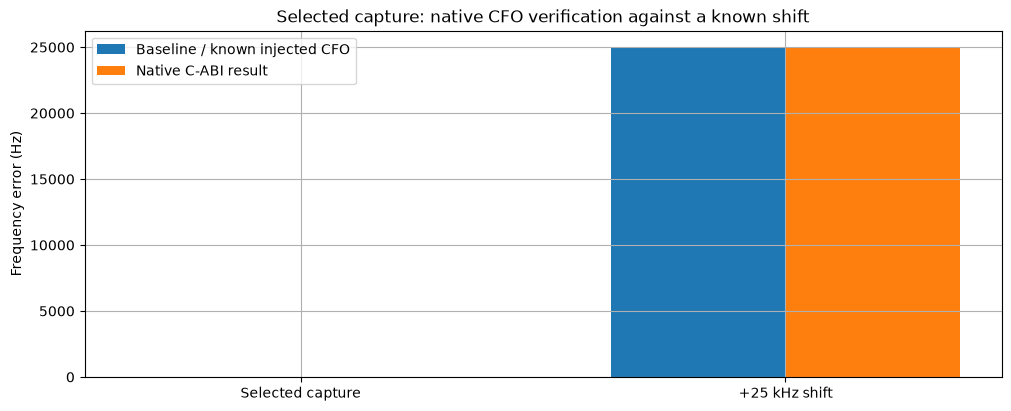

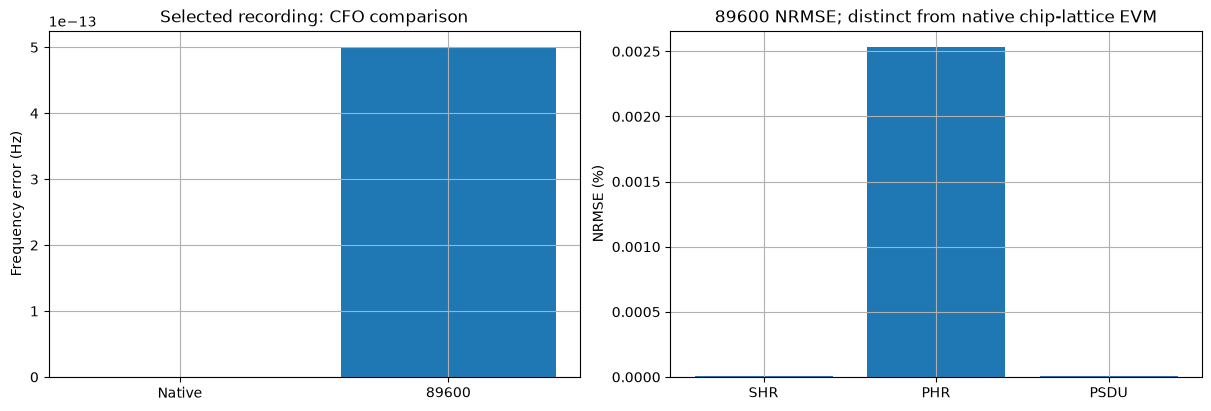

Verification report: reports\uwb_native_vsa_20261016.json


In [12]:
import hashlib
import json
import subprocess
from datetime import datetime, timezone

run_vsa_measurement = False
vsa_report = root / "reports/uwb_vsa_all_20261016.csv"
capture_relative = reference_capture.relative_to(root).as_posix()
capture_sha256 = hashlib.sha256(reference_capture.read_bytes()).hexdigest()
packet_config = 0 if mode == "802.15.4A" else int(settings["StsPacketConfig"])
vsa_command = [sys.executable, "-u", str(root / "tools/legacy_correlate.py"),
               "--only", f"802.15.4z_HrpUwb/{reference_capture.stem}"]
print("Optional VSA replay command:", subprocess.list2cmdline(vsa_command))
print("The saved report is used by default; live replay requires a running VSA and does not restart it.")
vsa_rows = []
if run_vsa_measurement:
    measurement_run = subprocess.run(vsa_command, cwd=root, capture_output=True, text=True, timeout=240)
    print(measurement_run.stdout)
    measurement_run.check_returncode()
    live_row = json.loads(next(line for line in reversed(measurement_run.stdout.splitlines()) if line.startswith("{")))
    live_row.update(capture=capture_relative, capture_sha256=capture_sha256,
                    measured_utc=datetime.now(timezone.utc).isoformat())
    vsa_rows = [live_row]
elif vsa_report.exists() and vsa_report.stat().st_size:
    with vsa_report.open(newline="", encoding="utf-8-sig") as stream:
        vsa_rows = [row for row in csv.DictReader(stream)
                    if row.get("family") == "802.15.4z_HrpUwb"
                    and row.get("waveform") == reference_capture.stem
                    and row.get("capture") == capture_relative]
correlation = None
vsa_tables = None
vsa_row = vsa_rows[-1] if vsa_rows else {}
vsa_status = "not_verified"
vsa_note = "No completed VSA measurement for the selected capture."
if vsa_row:
    if vsa_row.get("capture_sha256") != capture_sha256:
        vsa_status = "stale_capture"
        vsa_note = "The VSA row's SHA256 does not match the current capture; comparison rejected."
    elif vsa_row.get("status") == "ok" and vsa_row.get("vsa_all"):
        vsa_tables = json.loads(vsa_row["vsa_all"])
        correlation = check_uwb_correlation(reference_result.as_dict(), vsa_tables, packet_config=packet_config)
        vsa_status = "pass" if correlation["pass"] else "fail"
        vsa_note = "Native/VSA CFO compared; NRMSE values are VSA-only measurements of the same hashed capture."
        print(json.dumps(correlation, indent=2))
    else:
        vsa_status = "unsupported" if vsa_row.get("status") == "unsupported" else "not_verified"
        vsa_note = f"VSA attempt status {vsa_row.get('status')}: {vsa_row.get('note', '')}"
print(f"89600 correlation: {vsa_status.upper()} -- {vsa_note}")

figure, axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
positions = np.arange(2)
axis.bar(positions - 0.18, [reference_result.frequencyErrorHz, reference_result.frequencyErrorHz + injected_cfo_hz],
         width=0.36, label="Baseline / known injected CFO")
axis.bar(positions + 0.18, [reference_result.frequencyErrorHz, shifted_reference_result.frequencyErrorHz],
         width=0.36, label="Native C-ABI result")
axis.set(xticks=positions, xticklabels=["Selected capture", "+25 kHz shift"], ylabel="Frequency error (Hz)",
         title="Selected capture: native CFO verification against a known shift")
axis.legend()
plt.show()
if correlation is not None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    axes[0].bar(["Native", "89600"], [correlation["native_frequency_error_hz"], correlation["vsa_frequency_error_hz"]])
    axes[0].set(ylabel="Frequency error (Hz)", title="Selected recording: CFO comparison")
    quality_fields = [(label, field) for label, field in [("SHR", "ShrNrmse"), ("PHR", "PhrNrmse"),
                                                         ("PSDU", "PsduNrmse"), ("STS", "StsNrmse")]
                      if field in vsa_tables]
    axes[1].bar([entry[0] for entry in quality_fields], [vsa_tables[entry[1]] for entry in quality_fields])
    axes[1].set(ylabel="NRMSE (%)", title="89600 NRMSE; distinct from native chip-lattice EVM")
    plt.show()

verification = {"timestamp_utc": datetime.now(timezone.utc).isoformat(),
                "capture": capture_relative, "capture_sha256": capture_sha256,
                "native_version": demod.version(), "native_metrics": reference_result.as_dict(),
                "native_config": {"phyMode": reference_config.phyMode, "syncLength": reference_config.syncLength,
                                  "sampleRate": reference_config.sampleRate, "chipRateHz": reference_config.chipRateHz},
                "native_frame_metrics": frame_result.as_dict(), "native_frame_checks": frame_checks,
                "legacy_hopping_convention": settings.get("LegacyHoppingConvention"),
                "native_checks": {"reference_sync": True, "injected_cfo_hz": injected_cfo_hz,
                                  "recovered_cfo_shift_hz": measured_cfo_shift_hz, "empty_input_rejected": True},
                "cmake_unit_tests": "not_run: this notebook does not execute the CMake test suite",
                "vsa_source_csv": None if run_vsa_measurement else vsa_report.relative_to(root).as_posix(),
                "vsa_measured_utc": vsa_row.get("measured_utc"),
                "vsa_status": vsa_status, "vsa_note": vsa_note, "vsa_tables": vsa_tables,
                "correlation": correlation,
                "limitations": "Native legacy/BPRF/HPRF/EHPRF frames, optional MAC CRC-16/CRC-32 and chip-lattice EVM are implemented. Native EVM is not VSA-equivalent NRMSE. Random fixture PSDUs leave MAC FCS checking disabled. EHPRF follows the reference draft format; this VSA release has no EHPRF mode."}
verification_path = root / "reports/uwb_native_vsa_20261016.json"
verification_path.parent.mkdir(parents=True, exist_ok=True)
verification_path.write_text(json.dumps(verification, indent=2) + "\n", encoding="utf-8")
print(f"Verification report: {verification_path.relative_to(root)}")

In [13]:
# 10. Verify every distinct readable UWB capture, retaining failures and unsupported modes.
import re
import json
from datetime import datetime, timezone
from nrdemod.vsa import load_iq

batch_native_modes = {"BPRF": demod.UWB_BPRF, "HPRF": demod.UWB_HPRF,
                      "EHPRF": demod.UWB_EHPRF, "802.15.4a": demod.UWB_BPRF}
uwb_capture_paths = sorted([
    *(root / "captures/generated/uwb").glob("*.txt"),
    *(root / "captures/tdc_reference_plaintext/802.15.4z_HrpUwb").glob("*.txt"),
])
uwb_batch_rows = []
uwb_batch_native_path = root / "reports/uwb_all_20261016_native.json"
for waveform_path in uwb_capture_paths:
    generated = waveform_path.parent.name == "uwb"
    parameter_path = (waveform_path.with_suffix(".para2") if generated else
                      root / "captures/tdc_reference/802.15.4z_HrpUwb" / waveform_path.with_suffix(".para2").name)
    parameters = {}
    with parameter_path.open(newline="", encoding="utf-8-sig") as stream:
        for entry in csv.reader(stream, skipinitialspace=True):
            if len(entry) >= 4 and entry[0].strip() == "INPUT":
                parameters[entry[1].strip()] = entry[3].strip()
    if generated:
        waveform_mode = parameters["Mode"]
        sync_length = int(parameters["SyncLength"])
        packet_config = int(parameters["StsPacketConfig"])
    else:
        match = re.match(r"802154HrpUwb_(BPRF|HPRF)_SP(\d)_Code(\d+)_Sync(\d+)_Delta(\d+)_SFD(\d+)", waveform_path.stem)
        if match is None:
            raise ValueError(f"Unknown reference naming: {waveform_path.name}")
        waveform_mode = match.group(1)
        packet_config = int(match.group(2))
        sync_length = int(match.group(4))
    row = {"capture": waveform_path.relative_to(root).as_posix(),
           "source": "generated" if generated else "tdc_reference_plaintext",
           "mode": waveform_mode, "packet_config": packet_config,
           "sync_length": sync_length, "native_status": "not_run", "native_metrics": None,
           "injected_cfo_hz": 25000.0, "recovered_cfo_shift_hz": None,
           "cfo_test_pass": None, "vsa_status": "not_verified", "correlation_status": "not_verified", "note": ""}
    if waveform_mode not in batch_native_modes:
        row.update(native_status="unsupported", note=f"Unsupported PHY mode: {waveform_mode}")
    else:
        try:
            batch_iq, batch_fs = load_iq(str(waveform_path))
            if batch_fs is None or batch_fs <= 0:
                raise ValueError("Capture has no valid sample rate")
            batch_config = demod.Config(sampleRate=batch_fs, phyMode=batch_native_modes[waveform_mode],
                                        syncLength=sync_length)
            batch_result = demod.demodulate(demod.UWB_HRP, batch_iq, batch_config)
            row.update(sample_rate_hz=batch_fs, num_samples=batch_iq.size, native_phy_mode=batch_config.phyMode,
                       native_metrics=batch_result.as_dict())
            if batch_result.ok and batch_result.burstFound and batch_result.syncFound:
                batch_shifted = batch_iq * np.exp(2j * np.pi * row["injected_cfo_hz"] * np.arange(batch_iq.size) / batch_fs)
                batch_shift_result = demod.demodulate(demod.UWB_HRP, batch_shifted, batch_config)
                recovered = float(batch_shift_result.frequencyErrorHz - batch_result.frequencyErrorHz)
                cfo_pass = bool(batch_shift_result.ok and batch_shift_result.syncFound and np.isfinite(recovered)
                                and abs(recovered - row["injected_cfo_hz"]) <= 100)
                row.update(native_status="pass" if cfo_pass else "fail", recovered_cfo_shift_hz=recovered,
                           cfo_test_pass=cfo_pass)
                del batch_shifted
            else:
                row.update(native_status="fail", note=batch_result.error or "Native burst/preamble synchronization failed")
            del batch_iq
        except Exception as error:
            row.update(native_status="error", note=f"{type(error).__name__}: {error}")
    uwb_batch_rows.append(row)
    uwb_batch_native_path.write_text(json.dumps({"timestamp_utc": datetime.now(timezone.utc).isoformat(),
                                                 "native_version": demod.version(), "rows": uwb_batch_rows}, indent=2) + "\n",
                                      encoding="utf-8")
    print(f"{waveform_path.name}: native={row['native_status']}, CFO check={row['cfo_test_pass']}")

print(f"Distinct plaintext captures: {len(uwb_batch_rows)}")
print({status: sum(row["native_status"] == status for row in uwb_batch_rows)
       for status in ("pass", "fail", "error", "unsupported")})
print("Native checks cover repetition synchronization and CFO only, not code-index verification or payload decoding.")

UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt: native=pass, CFO check=True
UWB_4ab_EHPRF_ch5_7M8_LDPC_PSDU127.txt: native=pass, CFO check=True
UWB_4ab_EHPRF_ch9_124M8_LDPC_PSDU1024.txt: native=pass, CFO check=True
UWB_4ab_EHPRF_ch9_62M4_BCC_PSDU256.txt: native=pass, CFO check=True
UWB_4z_BPRF_ch5_CI10_SP1_PSDU127.txt: native=pass, CFO check=True
UWB_4z_BPRF_ch9_CI11_SP3.txt: native=pass, CFO check=True
UWB_4z_BPRF_ch9_CI9_SP0_PSDU127.txt: native=pass, CFO check=True
UWB_4z_HPRF_ch5_CI27_124M8_PSDU100.txt: native=pass, CFO check=True
UWB_4z_HPRF_ch9_CI25_249M6_PSDU127.txt: native=pass, CFO check=True
802154HrpUwb_BPRF_SP0_Code9_Sync64_Delta4_SFD0_PDR-L_FrameLeng127_RRCMinPhase_OSR4.txt: native=pass, CFO check=True
802154HrpUwb_BPRF_SP1_Code9_Sync64_Delta4_SFD2_PDR-L_FrameLeng127_STS-SegLen64-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True
802154HrpUwb_BPRF_SP3_Code9_Sync64_Delta4_SFD2_STS-SegLen64-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True
802154HrpUwb_HPRF_SP0_Code25

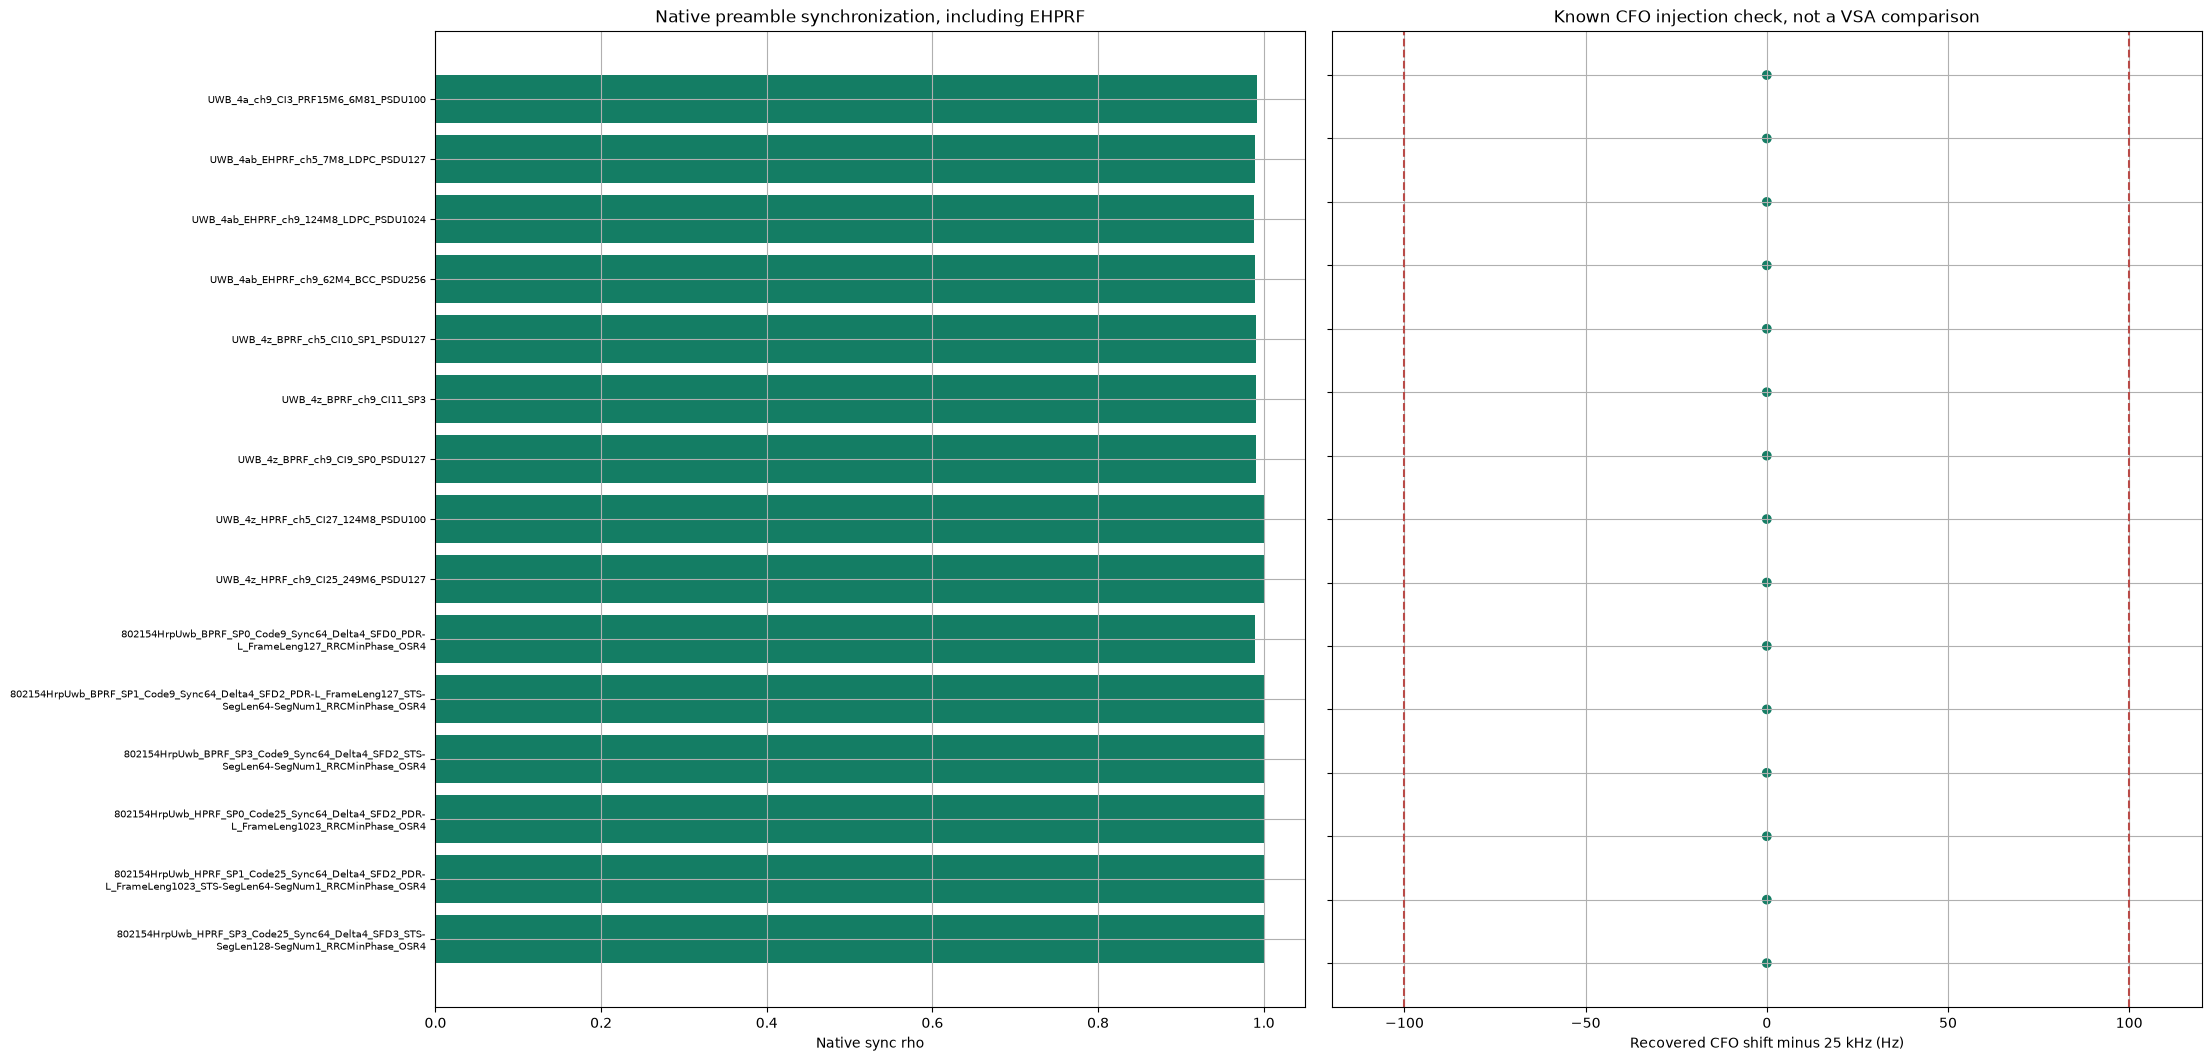

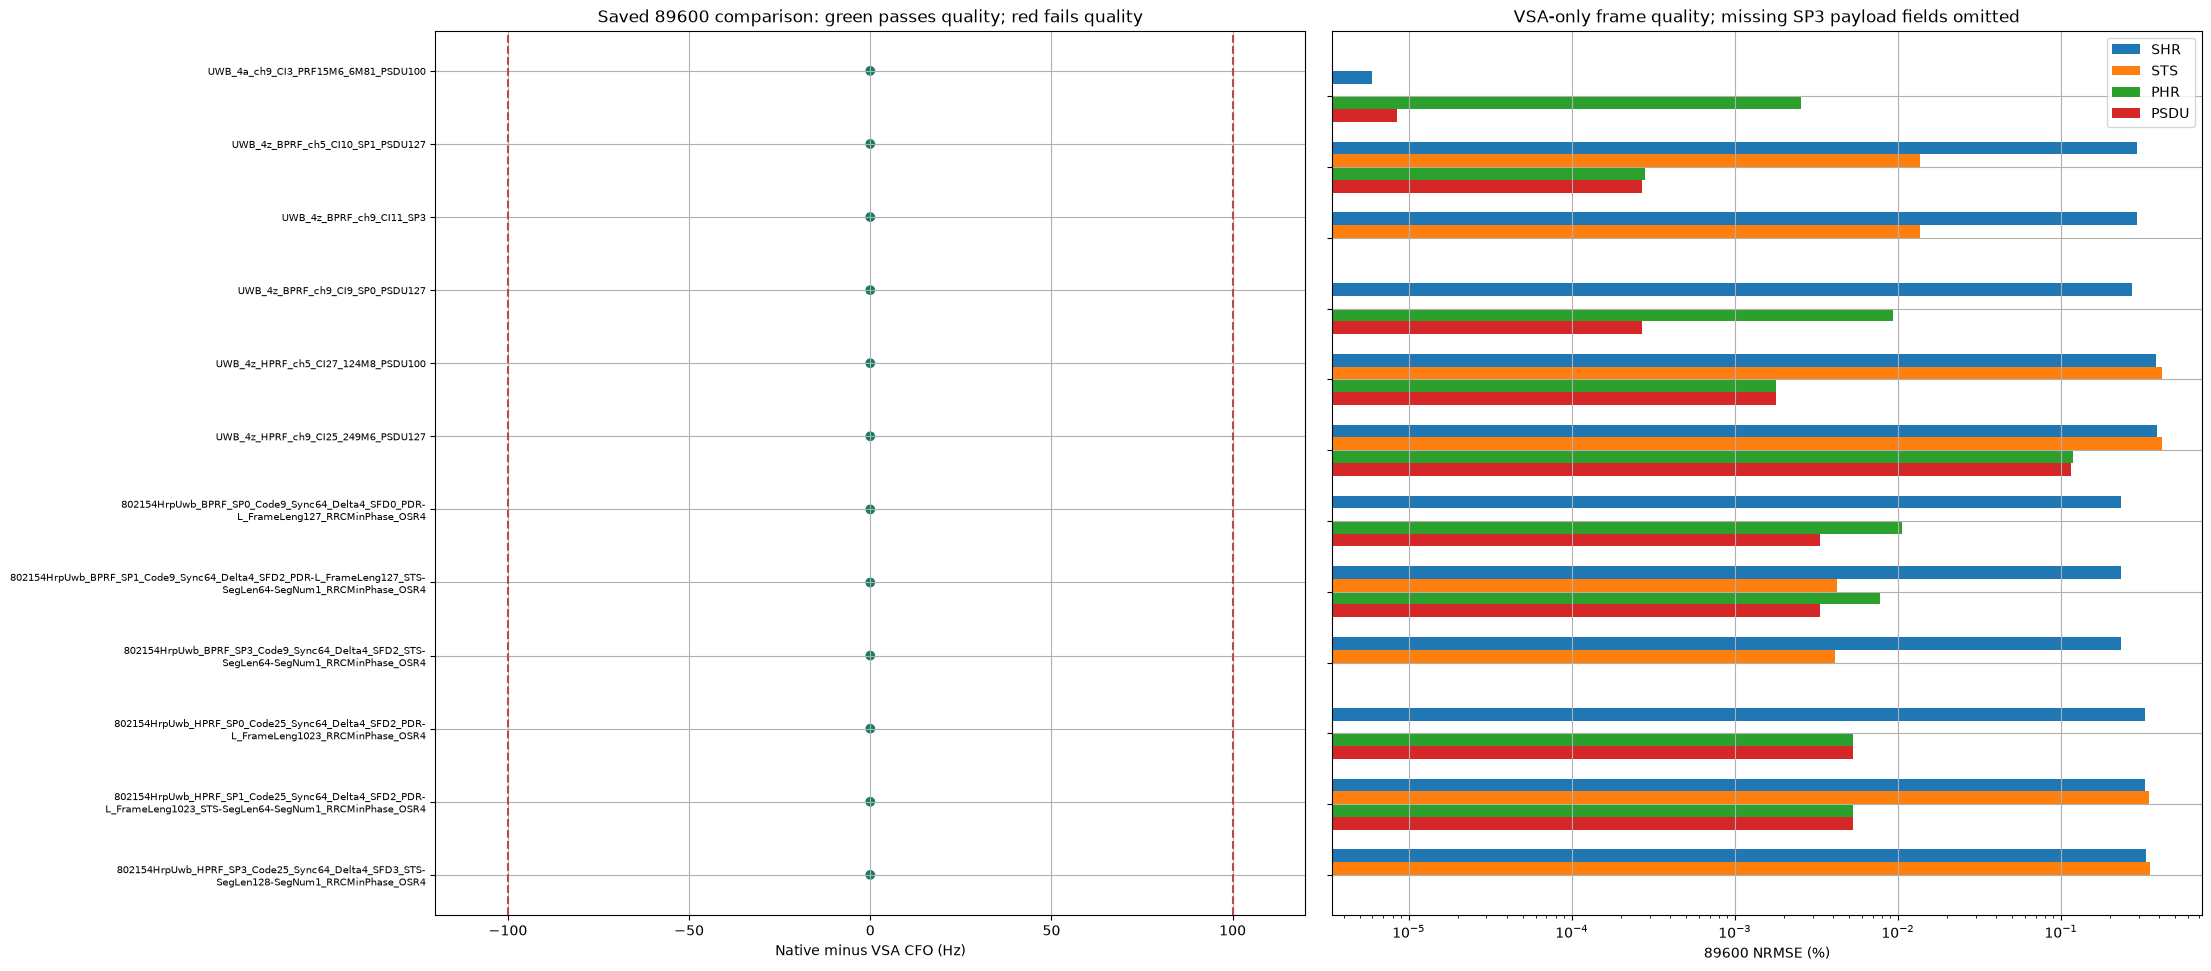

Summary: {'captures': 15, 'native_pass': 15, 'native_frame_pass': 9, 'correlation_pass': 12, 'correlation_fail': 0, 'vsa_unsupported': 3, 'vsa_invalid_results': 0}
VSA raw rows: 15 | valid CFO comparisons: 12
Limits: CFO difference <= 100 Hz; SHR/STS <= 0.5%; PHR/PSDU <= 2%.
EHPRF has native BCC/LDPC frame decoding and EVM; this VSA release has no EHPRF PHY mode.
Reports: reports\uwb_all_20261016.json reports\uwb_all_20261016.csv


In [14]:
import textwrap

connection_path = root / "reports/uwb_all_20261016_vsa_connection.json"
connection_attempt = (json.loads(connection_path.read_text(encoding="utf-8")) if connection_path.exists()
                      else {"status": "not_attempted"})
measurement_path = root / "reports/uwb_vsa_all_20261016.csv"
measurement_rows = {}
if measurement_path.exists():
    with measurement_path.open(newline="", encoding="utf-8-sig") as stream:
        measurement_rows = {row["capture"]: row for row in csv.DictReader(stream)}
batch_report_rows = []
for native_row in uwb_batch_rows:
    report_row = dict(native_row)
    measured = measurement_rows.get(report_row["capture"])
    report_row.update(vsa_status="not_run", correlation_status="not_verified", correlation=None,
                      vsa_measured_utc=None, vsa_tables=None,
                      vsa_note="No saved VSA measurement for this capture; connection alone is not a correlation.")
    if measured:
        report_row.update(vsa_status=measured["status"], vsa_measured_utc=measured["measured_utc"],
                          vsa_note=measured.get("note", ""))
        if measured["status"] == "ok" and measured.get("vsa_all"):
            with (root / report_row["capture"]).open("rb") as stream:
                capture_digest = hashlib.file_digest(stream, "sha256").hexdigest()
            report_row["capture_sha256"] = capture_digest
            if capture_digest != measured.get("capture_sha256"):
                report_row.update(vsa_status="input_mismatch", vsa_note="Capture changed since the saved VSA measurement.")
            else:
                tables = json.loads(measured["vsa_all"])
                report_row["vsa_tables"] = tables
                packet_config = 0 if report_row["mode"] == "802.15.4a" else report_row["packet_config"]
                try:
                    checked = check_uwb_correlation(report_row["native_metrics"], tables, packet_config=packet_config)
                    report_row.update(vsa_status="measured", correlation_status="pass" if checked["pass"] else "fail",
                                      correlation=checked, vsa_note="CFO compared on identical IQ; VSA NRMSE and native chip-lattice EVM use different methods.")
                    if not checked["vsa_lock_quality_pass"]:
                        failed_quality = [name for name, limit in checked["limits_percent"].items()
                                          if name in tables and not 0 <= float(tables[name]) <= limit]
                        report_row["vsa_note"] = "VSA quality checks failed: " + ", ".join(failed_quality) + "; waveform/setup compatibility needs investigation."
                except (ValueError, TypeError) as error:
                    report_row.update(vsa_status="invalid_results", correlation_status="fail", vsa_note=str(error))
    batch_report_rows.append(report_row)

batch_summary = {"captures": len(batch_report_rows),
                 "native_pass": sum(row["native_status"] == "pass" for row in batch_report_rows),
                 "native_frame_pass": sum(row["passed"] for row in frame_checks),
                 "correlation_pass": sum(row["correlation_status"] == "pass" for row in batch_report_rows),
                 "correlation_fail": sum(row["correlation_status"] == "fail" for row in batch_report_rows),
                 "vsa_unsupported": sum(row["vsa_status"] == "unsupported" for row in batch_report_rows),
                 "vsa_invalid_results": sum(row["vsa_status"] == "invalid_results" for row in batch_report_rows)}
batch_report = {"timestamp_utc": datetime.now(timezone.utc).isoformat(), "summary": batch_summary,
                "native_version": demod.version(), "vsa_connection_attempt": connection_attempt,
                "vsa_source_csv": str(measurement_path.relative_to(root)), "native_frame_checks": frame_checks,
                "limits": {"cfo_difference_hz": 100.0, "shr_sts_nrmse_percent": 0.5, "phr_psdu_nrmse_percent": 2.0},
                "limitations": "Inventory rows check synchronization/CFO; nine separate legacy/BPRF/HPRF/EHPRF frame checks are in native_frame_checks. Native chip-lattice EVM is not VSA-equivalent NRMSE. Random fixture PSDUs have MAC FCS checking disabled; optional CRC-16/CRC-32 is tested with independent valid-FCS vectors. EHPRF implements the reference draft format. VSA has no EHPRF mode. Binary TDC waveforms share the listed plaintext recordings.",
                "rows": batch_report_rows}
batch_report_path = root / "reports/uwb_all_20261016.json"
batch_report_path.write_text(json.dumps(batch_report, indent=2) + "\n", encoding="utf-8")
batch_csv_path = root / "reports/uwb_all_20261016.csv"
fields = ["capture", "source", "mode", "packet_config", "native_phy_mode", "sync_length", "sample_rate_hz", "num_samples",
          "native_status", "native_sync_rho", "native_cfo_hz", "injected_cfo_hz", "recovered_cfo_shift_hz", "cfo_test_pass",
          "vsa_status", "correlation_status", "vsa_measured_utc", "vsa_cfo_hz", "cfo_difference_hz", "cfo_agreement_pass",
          "vsa_lock_quality_pass", "vsa_shr_nrmse_percent", "vsa_sts_nrmse_percent", "vsa_phr_nrmse_percent",
          "vsa_psdu_nrmse_percent", "capture_sha256", "note", "vsa_note"]
with batch_csv_path.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
    writer.writeheader()
    for report_row in batch_report_rows:
        metrics = report_row["native_metrics"] or {}
        checked = report_row["correlation"] or {}
        writer.writerow({**report_row, **checked, "native_sync_rho": metrics.get("syncRho"),
                         "native_cfo_hz": metrics.get("frequencyErrorHz"), "vsa_cfo_hz": checked.get("vsa_frequency_error_hz")})

plot_rows = [row for row in batch_report_rows if row["native_metrics"] is not None]
if plot_rows:
    figure, axes = plt.subplots(1, 2, figsize=(22, max(7, len(plot_rows) * 0.7)), constrained_layout=True)
    positions = np.arange(len(plot_rows))
    labels = [textwrap.fill(Path(row["capture"]).stem, width=70) for row in plot_rows]
    colors = ["#147d64" if row["native_status"] == "pass" else "#b94b48" for row in plot_rows]
    axes[0].barh(positions, [row["native_metrics"]["syncRho"] for row in plot_rows], color=colors)
    axes[0].set(yticks=positions, yticklabels=labels, xlim=(0, 1.05), xlabel="Native sync rho",
                title="Native preamble synchronization, including EHPRF")
    axes[0].tick_params(axis="y", labelsize=7)
    axes[0].invert_yaxis()
    errors = [row["recovered_cfo_shift_hz"] - row["injected_cfo_hz"]
              if row["recovered_cfo_shift_hz"] is not None else np.nan for row in plot_rows]
    axes[1].scatter(errors, positions, c=colors)
    axes[1].axvline(-100, color="#b94b48", linestyle="--")
    axes[1].axvline(100, color="#b94b48", linestyle="--")
    axes[1].set(yticks=positions, yticklabels=[], xlim=(-120, 120), xlabel="Recovered CFO shift minus 25 kHz (Hz)",
                title="Known CFO injection check, not a VSA comparison")
    axes[1].invert_yaxis()
    plt.show()

compared_rows = [row for row in batch_report_rows if row["correlation"] is not None]
if compared_rows:
    figure, axes = plt.subplots(1, 2, figsize=(22, max(7, len(compared_rows) * 0.8)), constrained_layout=True)
    positions = np.arange(len(compared_rows))
    labels = [textwrap.fill(Path(row["capture"]).stem, width=70) for row in compared_rows]
    colors = ["#147d64" if row["correlation_status"] == "pass" else "#b94b48" for row in compared_rows]
    axes[0].scatter([row["correlation"]["cfo_difference_hz"] for row in compared_rows], positions, c=colors)
    axes[0].axvline(-100, color="#b94b48", linestyle="--")
    axes[0].axvline(100, color="#b94b48", linestyle="--")
    axes[0].set(yticks=positions, yticklabels=labels, xlim=(-120, 120), xlabel="Native minus VSA CFO (Hz)",
                title="Saved 89600 comparison: green passes quality; red fails quality")
    axes[0].tick_params(axis="y", labelsize=7)
    axes[0].invert_yaxis()
    for offset, label in enumerate(("shr", "sts", "phr", "psdu")):
        values = [row["correlation"].get(f"vsa_{label}_nrmse_percent") for row in compared_rows]
        axes[1].barh(positions + (offset - 1.5) * 0.18, [value if value is not None else np.nan for value in values],
                     height=0.18, label=label.upper())
    axes[1].set(yticks=positions, yticklabels=[], xscale="log", xlabel="89600 NRMSE (%)",
                title="VSA-only frame quality; missing SP3 payload fields omitted")
    axes[1].invert_yaxis()
    axes[1].legend()
    plt.show()

print("Summary:", batch_summary)
print("VSA raw rows:", len(measurement_rows), "| valid CFO comparisons:", len(compared_rows))
print("Limits: CFO difference <= 100 Hz; SHR/STS <= 0.5%; PHR/PSDU <= 2%.")
print("EHPRF has native BCC/LDPC frame decoding and EVM; this VSA release has no EHPRF PHY mode.")
print("Reports:", batch_report_path.relative_to(root), batch_csv_path.relative_to(root))